# Same Channels, Different Insights?
## Comparing EEG Channel Selection for Motor Imagery Classification and Functional Connectivity

*Kanal yang Sama, Informasi Berbeda? Perbandingan Seleksi Kanal EEG untuk Klasifikasi Motor Imagery dan Functional Connectivity*

**Proyek UTS individu — Teknik Biomedis**
**Stage 2: pipeline eksperimen yang dapat dijalankan ulang**

---

### Abstrak

Electroencephalography (EEG) merekam aktivitas listrik otak dari kulit kepala menggunakan puluhan elektroda. Dalam *brain–computer interface* (BCI), kita sering ingin memakai **lebih sedikit kanal**: pemasangan lebih cepat, model lebih sederhana, dan risiko overfitting lebih kecil. Tetapi "kanal terbaik" bergantung pada **untuk apa** kanal itu dipilih. Notebook ini membandingkan tiga cara memilih delapan kanal dari sepuluh kandidat yang sudah ditetapkan sebelumnya: (1) subset anatomis sensorimotor yang tetap, (2) subset yang dipilih karena paling baik untuk **klasifikasi** *motor imagery* dengan CSP–LDA, dan (3) subset yang dipilih karena paling besar **perbedaan functional connectivity**-nya antara dua kelas, diukur dengan *debiased squared weighted phase lag index* (wPLI²). Semua pemilihan dilakukan hanya pada run latih, lalu dinilai pada run yang ditahan (*held-out run*) dalam subjek yang sama. Data berasal dari PhysioNet EEG Motor Movement/Imagery Database, subjek S001–S003, run 6, 10, dan 14 (imajinasi kedua kepalan tangan vs kedua kaki).

> **Pertanyaan pemandu notebook ini:**
> *Jika delapan kanal dipilih karena paling bagus untuk mengklasifikasikan imajinasi gerak, apakah delapan kanal yang sama juga paling informatif untuk melihat perbedaan hubungan antar-sinyal (functional connectivity)?*

Semua angka yang muncul dalam notebook ini dihasilkan oleh kode di dalamnya. Teks yang bergantung pada hasil ditulis secara **terprogram** (dihasilkan dari tabel hasil), bukan diketik tangan, supaya tidak ada angka yang "mengarang".

## 00 — Pendahuluan dan peta penelitian

### Latar belakang dan motivasi

Seleksi kanal untuk motor imagery (MI) adalah topik yang mapan. Review Abdullah dkk. [abdullah2022] merangkum tiga tujuannya: menurunkan kompleksitas komputasi, mengurangi overfitting, dan mempersingkat waktu pemasangan elektroda. Sebagian besar metode menilai subset kanal dengan satu kriteria saja, biasanya **akurasi klasifikasi** (misalnya CSP-rank pada Feng dkk. [feng2019]).

Di sisi lain, ada kelompok metode yang memakai **hubungan antar-kanal** untuk memilih kanal: koefisien korelasi [parkchung2020], Granger causality [varsehi2021], dan graf functional connectivity [lou2023; liang2023]. Jadi, menghubungkan konektivitas dengan pemilihan kanal **bukan ide baru**.

### Paper acuan dan celah penelitian

**Anchor utama:** Lou, Ye, Yao & Zhang (2023), *Less Is More: Brain Functional Connectivity Empowered Generalizable Intention Classification With Task-Relevant Channel Selection* [lou2023]. Mereka memakai functional connectivity untuk memilih kanal pada dataset yang sama (EEGMMI). Rincian algoritma mereka **belum diaudit dari teks lengkap** pada Stage 1, sehingga notebook ini tidak menguraikan metodenya sebagai fakta terverifikasi.

**Celah terbatas** (sejauh yang ditelusuri di Stage 1, bukan klaim "belum pernah ada"): dalam sumber yang ditinjau belum terdeteksi evaluasi eksplisit apakah subset terbaik-klasifikasi **juga** membawa diskriminasi konektivitas pada *run yang belum dilihat*, dibandingkan dengan subset terbaik-konektivitas dan baseline anatomis. Kontribusi proyek ini adalah **desain evaluasi silang yang transparan**, bukan metode seleksi kanal baru.

### Pertanyaan penelitian dan hipotesis kerja

| ID | Pertanyaan | Hipotesis kerja (eksploratif, tidak harus terbukti) | Output |
|---|---|---|---|
| RQ1 | Seberapa sama kanal yang dipilih oleh dua kriteria? | H1: subset tidak selalu identik | Jaccard dan peta kanal |
| RQ2 | Apakah seleksi berbasis klasifikasi memperbaiki balanced accuracy (BA) uji dibanding baseline anatomis? | H2: BA CLS cenderung ≥ baseline | BA per fold/subjek, tanpa klaim superioritas inferensial |
| RQ3 | Apakah subset CLS tetap menangkap perbedaan konektivitas held-out dibanding subset CONN? | H3: CDS CLS dapat berbeda dari CDS CONN | CDS pada run uji |
| RQ4 (opsional) | Apakah skor klasifikasi dan CDS berkaitan di antara kandidat? | H4: ada asosiasi, arah belum ditentukan | Spearman deskriptif pada skor **latih** 10 subset |

Dengan tiga subjek, semua pertanyaan dijawab secara **deskriptif dan eksploratif**. Tidak ada klaim "signifikan".

### Gambaran pipeline

```
EDF PhysioNet (S001–S003, run 6/10/14)
   │  verifikasi: 160 Hz, 64 kanal, anotasi T0/T1/T2, jumlah trial
   ▼
QC 64 kanal  →  band-pass 7–30 Hz per run  →  epoch 1,0–2,5 s (T1=hands, T2=feet)
   ▼
10 kandidat subset × 8 kanal (ditetapkan sebelum melihat data)
   ▼
Untuk setiap subjek, untuk setiap run uji (leave-one-run-out):
   ├─ data latih (2 run) ──► S_CLS  = argmax BA validasi silang dalam (run A↔B), CSP–LDA
   │                     └─► S_CONN = argmax CDS latih (debiased wPLI², 8–12 Hz)
   │                     └─► S01    = baseline anatomis (tetap)
   └─ run uji (ditahan) ──► BA uji + CDS uji untuk S01, S_CLS, S_CONN
   ▼
Perbandingan: BA (RQ2), CDS held-out (RQ3), Jaccard (RQ1), Spearman latih (RQ4)
```

Dokumen pendamping: `PROJECT_SPEC.md` (kontrak metodologis, otoritas utama), `THEORETICAL_FRAMEWORK.md`, `LITERATURE_REVIEW.md`, `references.bib`.

### Persiapan: pustaka dan konfigurasi

Sel berikut memuat pustaka dan **semua parameter eksperimen di satu tempat**. Parameter ini ditetapkan dari `PROJECT_SPEC.md` sebelum skor apa pun dihitung. Jika ingin menjalankan ulang dengan subjek berbeda, cukup ubah variabel lingkungan `SCDI_SUBJECTS` (misalnya `SCDI_SUBJECTS=1` untuk *smoke test*), bukan kode di bawah.

In [1]:
import os, json, time, hashlib, platform, warnings, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Circle, Polygon
import networkx as nx
import mne
import mne_connectivity
from mne.datasets import eegbci
from mne.decoding import CSP
from mne_connectivity import spectral_connectivity_epochs
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from scipy.stats import spearmanr
from IPython.display import display, Markdown

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore", category=FutureWarning)

def show_md(text):
    # Menampilkan teks Markdown yang dibangun dari hasil komputasi (bukan diketik tangan)
    display(Markdown(text))

In [2]:
# ---------------- Parameter eksperimen (dari PROJECT_SPEC.md) ----------------
SUBJECTS = [int(s) for s in os.environ.get("SCDI_SUBJECTS", "1,2,3").split(",")]
RUNS = [6, 10, 14]                      # imagined both fists (T1) vs both feet (T2)
EVENT_ID = {"hands": 1, "feet": 2}      # T1 -> hands, T2 -> feet; T0 (rest) dikeluarkan
LABEL_NAMES = ["hands", "feet"]         # kode kelas y: 0 = hands, 1 = feet
SEED = 20261019                         # seed global untuk semua pengacakan

L_FREQ, H_FREQ = 7.0, 30.0              # band-pass umum (Hz)
TMIN, TMAX = 1.0, 2.5                   # jendela epoch relatif onset (s)
CONN_FMIN, CONN_FMAX = 8.0, 12.0        # band konektivitas (Hz)
CSP_N_COMPONENTS = 4
REJECT_PTP_UV = 400.0                   # ambang penolakan epoch (peak-to-peak, µV); lihat bagian 04
N_PERMUTATIONS = int(os.environ.get("SCDI_N_PERM", "100"))   # null permutasi untuk audit CDSx

# ---------------- Lokasi file ----------------
DATA_PATH = Path(os.environ.get("SCDI_DATA", Path.home() / "mne_data"))
PROJECT_DIR = Path.cwd()
OUT_DIR = PROJECT_DIR / "outputs"
FIG_DIR = OUT_DIR / "figures"
for folder in (DATA_PATH, OUT_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Montage 10–05. Pada MNE >= 1.13 nama 'standard_1005' diganti 'colin27_1005' (posisi sama).
MONTAGE_NAME = "colin27_1005" if "colin27_1005" in mne.channels.get_builtin_montages() else "standard_1005"

# ---------------- Gaya gambar ----------------
APPROACHES = ["ANATOMICAL", "CLS", "CONN"]
APPROACH_COLORS = {"ANATOMICAL": "#2a78d6", "CLS": "#eb6834", "CONN": "#1baf7a"}
CLASS_COLORS = {"hands": "#6250d6", "feet": "#c98500"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
    "axes.titlesize": 11, "axes.labelsize": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": False, "legend.frameon": False,
})

def save_fig(fig, filename):
    path = FIG_DIR / filename
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    print("Gambar tersimpan:", path.relative_to(PROJECT_DIR))

print("Subjek:", SUBJECTS, "| Run:", RUNS, "| Permutasi:", N_PERMUTATIONS, "| Montage:", MONTAGE_NAME)
print("MNE", mne.__version__, "| MNE-Connectivity", mne_connectivity.__version__,
      "| scikit-learn", sklearn.__version__, "| NumPy", np.__version__)

Subjek: [1, 2, 3] | Run: [6, 10, 14] | Permutasi: 100 | Montage: colin27_1005
MNE 1.13.2 | MNE-Connectivity 0.9.0 | scikit-learn 1.9.1 | NumPy 2.5.3


Dengan pertanyaan dan alat sudah jelas, kita perlu memahami **apa sebenarnya yang direkam EEG**. Tanpa itu, sulit menilai mengapa dua cara memilih kanal bisa memberi jawaban berbeda.

---

## 01 — Memahami EEG dan motor imagery

> **Pertanyaan:** ketika seseorang hanya *membayangkan* menggerakkan tangan, apa yang berubah pada sinyal di kulit kepalanya, dan mengapa perubahan itu bisa dilihat dengan dua cara berbeda?

### Apa yang diukur EEG?

Neuron berkomunikasi lewat arus ion. Ketika ribuan neuron piramidal di korteks menerima input sinaptik secara serentak, arus kecil itu menjumlah menjadi medan listrik yang cukup besar untuk terukur di kulit kepala. Kontributor utama sinyal ekstraseluler adalah arus sinaptik, meskipun sumber lain juga ikut membentuk medan [buzsaki2012].

Bayangkan sebuah stadion. Satu orang bersorak tidak terdengar dari luar, tetapi ribuan orang yang bersorak **bersamaan** terdengar jelas. EEG hanya "mendengar" sorakan yang serentak.

### Bagaimana elektroda merekam?

Setiap elektroda mengukur **beda potensial** antara titiknya dan titik referensi, dalam mikrovolt (µV). Masalahnya, medan listrik menyebar melalui otak, cairan, tengkorak, dan kulit. Akibatnya setiap elektroda menangkap **campuran** banyak sumber. Fenomena ini disebut **volume conduction**, dan membuat gambaran EEG multikanal "kabur" [blankertz2008]. Satu konsekuensi penting untuk proyek ini: dua elektroda bisa tampak berhubungan karena **menangkap sumber yang sama**, bukan karena dua area otak saling berinteraksi [nolte2004; vinck2011].

### Otak saat membayangkan gerak: sensorimotor rhythm dan ERD/ERS

Saat istirahat, korteks sensorimotor cenderung berosilasi pada ritme **mu (8–13 Hz)** dan **beta (13–30 Hz)**. Ketika kita bergerak, atau hanya membayangkan bergerak, populasi neuron di area terkait berhenti berosilasi serentak, sehingga daya pita itu **turun**. Penurunan ini disebut **event-related desynchronization (ERD)**; kenaikan daya disebut **event-related synchronization (ERS)** [pfurtscheller1999]. Untuk MI, perubahan ini muncul di area sensorimotor pada pita mu dan beta, sehingga band-pass sekitar 8–30 Hz lazim dipakai [feng2019].

Secara kasar, representasi tangan berada di korteks sensorimotor lateral (dekat elektroda C3 dan C4), sedangkan kaki di bagian medial dekat garis tengah (dekat Cz). Karena itu kelas **hands** dan **feet** diharapkan menghasilkan pola ERD yang **berbeda secara spasial**.

### Mengapa klasifikasi dan konektivitas bisa melihat hal berbeda?

Dua cabang analisis memakai **statistik berbeda** dari sinyal yang sama:

| Cabang | Yang diukur | Kanal "bagus" adalah kanal yang… |
|---|---|---|
| Klasifikasi (CSP–LDA) | **daya/varians lokal** setiap sinyal | menunjukkan perubahan daya (ERD) yang berbeda antar-kelas |
| Konektivitas (wPLI²) | **konsistensi selisih fase** antar pasangan sinyal | pasangannya menunjukkan pola sinkronisasi fase yang berbeda antar-kelas |

Analogi: dua orang penonton konser. Penonton pertama menilai *seberapa keras* setiap pemain musik. Penonton kedua menilai *seberapa kompak* para pemain bermain bersama. Pemain yang paling keras belum tentu yang paling kompak. Notebook ini menguji apakah hal serupa terjadi pada kanal EEG.

Dua kemungkinan diuji tanpa memihak (lihat `THEORETICAL_FRAMEWORK.md` §3.4):
- **Konvergen:** keduanya digerakkan faktor bersama (misalnya SNR pita mu di area sensorimotor), sehingga subset terbaik-klasifikasi juga membawa diskriminasi konektivitas. Konvergensi semacam itu **bukan bukti kopling saraf**.
- **Divergen:** keduanya menangkap aspek berbeda, sehingga satu subset tidak optimal untuk keduanya.

Untuk menguji ini, kita butuh data nyata. Langkah berikutnya adalah mengambil dan memverifikasi rekaman PhysioNet.

---

## 02 — Akuisisi data PhysioNet

> **Pertanyaan:** apakah data yang kita unduh benar-benar seperti yang dijanjikan dokumentasinya: 64 kanal, 160 Hz, dan event imajinasi tangan/kaki dengan jumlah yang cukup?

### PhysioNet dan dataset EEG Motor Movement/Imagery

PhysioNet adalah repositori terbuka untuk sinyal fisiologis [goldberger2000]. Dataset *EEG Motor Movement/Imagery* [physionet_eegmmi] berisi rekaman 109 relawan, direkam dengan sistem BCI2000 [schalk2004] menggunakan 64 elektroda sistem 10–10 pada 160 Hz, disimpan dalam format **EDF+**.

Setiap subjek menjalani 14 **run** (sesi rekaman pendek ±2 menit). Arti label anotasi **berbeda antar-run**. Menurut dokumentasi resmi, pada run **6, 10, dan 14** subjek *membayangkan* membuka-menutup **kedua kepalan tangan** (T1) atau **kedua kaki** (T2); T0 adalah istirahat. Pada run lain, T1/T2 berarti tangan kiri/kanan. Karena itu run lain **tidak boleh** digabung tanpa pemetaan ulang label (PROJECT_SPEC §4).

### Istilah dasar

| Istilah | Arti dalam notebook ini |
|---|---|
| **Subjek** | Satu orang relawan (S001, S002, S003). Model tidak pernah dipakai lintas subjek. |
| **Run** | Satu rekaman kontinu ±125 s. Tiga run per subjek: 6, 10, 14. |
| **Event / anotasi** | Penanda waktu pada rekaman: kapan cue T0/T1/T2 muncul dan berapa lama. |
| **Kanal** | Sinyal dari satu elektroda (misalnya C3). |
| **Trial / epoch** | Potongan pendek sinyal di sekitar satu event T1 atau T2; satu epoch = satu sampel untuk classifier. |

### Strategi unduh

Kita memakai `mne.datasets.eegbci.load_data`, yang mengunduh dari physionet.org dan memeriksa hash file. Jika server itu tidak dapat dijangkau (misalnya di lingkungan dengan proxy), kode beralih ke **mirror resmi PhysioNet di AWS Open Data** (`physionet-open`) dan memverifikasi setiap file dengan daftar `SHA256SUMS.txt` resmi. Tidak ada data sintetis atau pengganti.

In [3]:
PHYSIONET_MIRROR = "https://physionet-open.s3.amazonaws.com/eegmmidb/1.0.0/"
EEGBCI_DIR = DATA_PATH / "MNE-eegbci-data" / "files" / "eegmmidb" / "1.0.0"

def official_sha256_table():
    # Daftar checksum resmi PhysioNet; None jika tidak dapat diunduh
    sums_file = DATA_PATH / "eegmmidb_SHA256SUMS.txt"
    try:
        if not sums_file.exists():
            urllib.request.urlretrieve(PHYSIONET_MIRROR + "SHA256SUMS.txt", sums_file)
        table = {}
        for line in sums_file.read_text().splitlines():
            if line.strip():
                digest, rel_path = line.split()
                table[rel_path] = digest
        return table
    except Exception as err:
        print("Checksum resmi tidak tersedia:", err)
        return None

def sha256_of(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def download_from_mirror(subject, runs):
    files = []
    for run in runs:
        rel_path = f"S{subject:03d}/S{subject:03d}R{run:02d}.edf"
        local = EEGBCI_DIR / rel_path
        local.parent.mkdir(parents=True, exist_ok=True)
        if not local.exists():
            urllib.request.urlretrieve(PHYSIONET_MIRROR + rel_path, local)
        files.append(local)
    return files

def load_edf_files(subject):
    try:
        files = eegbci.load_data(subject, runs=RUNS, path=DATA_PATH, update_path=False)
        source = "mne.datasets.eegbci (physionet.org)"
    except Exception as err:
        print(f"S{subject:03d}: unduhan MNE gagal ({type(err).__name__}); memakai mirror AWS resmi.")
        files = download_from_mirror(subject, RUNS)
        source = "physionet-open AWS mirror"
    return [Path(f) for f in files], source

sha_table = official_sha256_table()
edf_files, file_rows = {}, []
for subject in SUBJECTS:
    files, source = load_edf_files(subject)
    for run, path in zip(RUNS, files):
        assert path.name == f"S{subject:03d}R{run:02d}.edf", f"Urutan file tidak sesuai: {path.name}"
        rel_path = f"S{subject:03d}/{path.name}"
        digest = sha256_of(path)
        verified = None if sha_table is None else (sha_table.get(rel_path) == digest)
        edf_files[(subject, run)] = path
        file_rows.append({"subject": subject, "run": run, "file": path.name, "source": source,
                          "size_bytes": path.stat().st_size, "sha256_matches_official": verified})

file_table = pd.DataFrame(file_rows)
display(file_table)
assert sha_table is None or file_table["sha256_matches_official"].all(), "Ada file yang checksum-nya tidak cocok!"

,subject,run,file,source,size_bytes,sha256_matches_official
0,1,6,S001R06.edf,mne.datasets.eegbci (physionet.org),2596896,True
1,1,10,S001R10.edf,mne.datasets.eegbci (physionet.org),2596896,True
2,1,14,S001R14.edf,mne.datasets.eegbci (physionet.org),2596896,True
3,2,6,S002R06.edf,mne.datasets.eegbci (physionet.org),2555616,True
4,2,10,S002R10.edf,mne.datasets.eegbci (physionet.org),2555616,True
5,2,14,S002R14.edf,mne.datasets.eegbci (physionet.org),2555616,True
6,3,6,S003R06.edf,mne.datasets.eegbci (physionet.org),2596896,True
7,3,10,S003R10.edf,mne.datasets.eegbci (physionet.org),2596896,True
8,3,14,S003R14.edf,mne.datasets.eegbci (physionet.org),2596896,True


Kolom `sha256_matches_official = True` berarti isi file identik bit-per-bit dengan file yang dipublikasikan PhysioNet. Sekarang kita baca setiap file EDF secara **terpisah per run**, sehingga identitas run tidak pernah hilang (PROJECT_SPEC §5.1). Nama kanal di EDF ditulis dengan titik dan huruf yang tidak standar (misalnya `Fc5.`); `eegbci.standardize` mengubahnya ke penamaan 10–10 standar (`FC5`), lalu posisi 3D elektroda dipasang dari montage 10–05.

In [4]:
def read_run(subject, run):
    raw = mne.io.read_raw_edf(edf_files[(subject, run)], preload=True)
    original_names = list(raw.ch_names)
    eegbci.standardize(raw)
    raw.set_montage(MONTAGE_NAME)
    return raw, original_names

raws, metadata_rows = {}, []
for subject in SUBJECTS:
    for run in RUNS:
        raw, original_names = read_run(subject, run)
        raws[(subject, run)] = raw
        desc = raw.annotations.description
        cue = np.isin(desc, ["T1", "T2"])
        metadata_rows.append({
            "subject": f"S{subject:03d}", "run": run,
            "sfreq_Hz": raw.info["sfreq"],
            "n_channels": len(raw.ch_names),
            "n_eeg": len(mne.pick_types(raw.info, eeg=True)),
            "duration_s": round(raw.n_times / raw.info["sfreq"], 2),
            "n_T0": int(np.sum(desc == "T0")), "n_T1": int(np.sum(desc == "T1")), "n_T2": int(np.sum(desc == "T2")),
            "cue_duration_s": "/".join(f"{d:.1f}" for d in np.unique(np.round(raw.annotations.duration[cue], 1))),
            "median_abs_uV": round(float(np.median(np.abs(raw.get_data()))) * 1e6, 1),
            "example_rename": f"{original_names[0]} -> {raw.ch_names[0]}",
        })

recording_table = pd.DataFrame(metadata_rows)
display(recording_table)

,subject,run,sfreq_Hz,n_channels,n_eeg,duration_s,n_T0,n_T1,n_T2,cue_duration_s,median_abs_uV,example_rename
0,S001,6,160.0,64,64,125.0,15,7,8,4.1,34.0,Fc5. -> FC5
1,S001,10,160.0,64,64,125.0,15,7,8,4.1,32.0,Fc5. -> FC5
2,S001,14,160.0,64,64,125.0,15,7,8,4.1,32.0,Fc5. -> FC5
3,S002,6,160.0,64,64,123.0,15,8,7,4.1,16.0,Fc5. -> FC5
4,S002,10,160.0,64,64,123.0,15,8,7,4.1,12.0,Fc5. -> FC5
5,S002,14,160.0,64,64,123.0,15,8,7,4.1,12.0,Fc5. -> FC5
6,S003,6,160.0,64,64,125.0,15,7,8,4.1,45.0,Fc5. -> FC5
7,S003,10,160.0,64,64,125.0,15,7,8,4.1,40.0,Fc5. -> FC5
8,S003,14,160.0,64,64,125.0,15,7,8,4.1,40.0,Fc5. -> FC5


**Membaca tabel ini.** Setiap baris adalah satu run. Yang perlu dicek: `sfreq_Hz` harus 160, `n_eeg` harus 64, setiap run harus memuat T1 dan T2, dan `median_abs_uV` harus berada pada orde puluhan mikrovolt (tanda bahwa MNE sudah mengonversi satuan ke volt dengan benar, lalu kita tampilkan dalam µV). `cue_duration_s` menunjukkan berapa lama setiap cue imajinasi berlangsung; jendela epoch kita (1,0–2,5 s) harus **muat di dalam** durasi itu.

Sel berikut mengubah pengecekan visual itu menjadi **assertion**: jika satu saja syarat gagal, notebook berhenti dengan pesan yang jelas, bukan diam-diam melanjutkan dengan data yang salah (acceptance test AT-01 sampai AT-03).

In [5]:
for (subject, run), raw in raws.items():
    tag = f"S{subject:03d}R{run:02d}"
    assert run in (6, 10, 14), "Label T1/T2 = fists/feet hanya berlaku untuk run 6, 10, 14"
    assert raw.info["sfreq"] == 160.0, f"{tag}: sfreq bukan 160 Hz"
    assert len(mne.pick_types(raw.info, eeg=True)) == 64, f"{tag}: bukan 64 kanal EEG"
    assert set(raw.annotations.description) <= {"T0", "T1", "T2"}, f"{tag}: label anotasi tak dikenal"
    n_t1 = np.sum(raw.annotations.description == "T1"); n_t2 = np.sum(raw.annotations.description == "T2")
    assert n_t1 > 0 and n_t2 > 0, f"{tag}: kedua kelas harus ada"
    cue_dur = raw.annotations.duration[np.isin(raw.annotations.description, ["T1", "T2"])]
    assert cue_dur.min() >= TMAX, f"{tag}: durasi cue lebih pendek dari TMAX"

SFREQ = raws[(SUBJECTS[0], RUNS[0])].info["sfreq"]
CH_NAMES = raws[(SUBJECTS[0], RUNS[0])].ch_names
assert all(r.ch_names == CH_NAMES for r in raws.values()), "Urutan kanal berbeda antar-run"
print(f"Semua {len(raws)} run lolos verifikasi: 160 Hz, 64 kanal EEG, T1 dan T2 tersedia, cue >= {TMAX} s.")
print("Total cue T1 (hands):", int(recording_table.n_T1.sum()), "| T2 (feet):", int(recording_table.n_T2.sum()))

Semua 9 run lolos verifikasi: 160 Hz, 64 kanal EEG, T1 dan T2 tersedia, cue >= 2.5 s.
Total cue T1 (hands): 66 | T2 (feet): 69


**Interpretasi.** Setiap run hanya memuat sekitar 15 cue imajinasi (T1 + T2), jadi satu subjek menyumbang sekitar 45 trial. Ini **sedikit** untuk standar machine learning, dan akan membatasi dua hal: stabilitas classifier yang dilatih pada satu run (±15 trial) dan presisi estimasi konektivitas per kelas. Batasan ini dicatat sekarang agar tidak terlupa saat membaca hasil.

Data sudah terverifikasi secara administratif. Tetapi angka metadata belum memberi tahu **seperti apa** sinyalnya. Sebelum memproses apa pun, kita perlu melihat EEG mentah.

---

## 03 — Menjelajahi EEG mentah

> **Pertanyaan:** seperti apa EEG mentah, dan mengapa kita tidak bisa langsung memasukkannya ke classifier?

### Empat konsep untuk membaca sinyal

- **Amplitudo (µV):** seberapa besar beda potensial. EEG kulit kepala biasanya puluhan µV, sejuta kali lebih kecil dari tegangan baterai AA.
- **Waktu dan sampling rate:** EEG dicatat 160 kali per detik (160 Hz), jadi jarak antar-sampel 6,25 ms. Menurut teorema Nyquist, frekuensi tertinggi yang dapat direpresentasikan adalah $f_s/2 = 80$ Hz.
- **Frekuensi:** sinyal EEG adalah campuran banyak osilasi. Pita yang relevan di sini adalah mu (8–13 Hz) dan beta (13–30 Hz).
- **Noise:** apa saja yang bukan aktivitas otak yang kita cari, misalnya kedipan mata (besar, lambat, di kanal frontal), ketegangan otot (frekuensi tinggi), drift elektroda (sangat lambat), dan interferensi listrik 60 Hz (jaringan listrik Amerika Serikat, tempat data direkam).

Gambar berikut menampilkan 16 detik pertama dari satu run, pada delapan kanal yang tersebar dari depan (Fp1) sampai belakang (O1). Area berwarna menandai cue imajinasi.

Gambar tersimpan: outputs/figures/01_raw_eeg_S001_R06.png


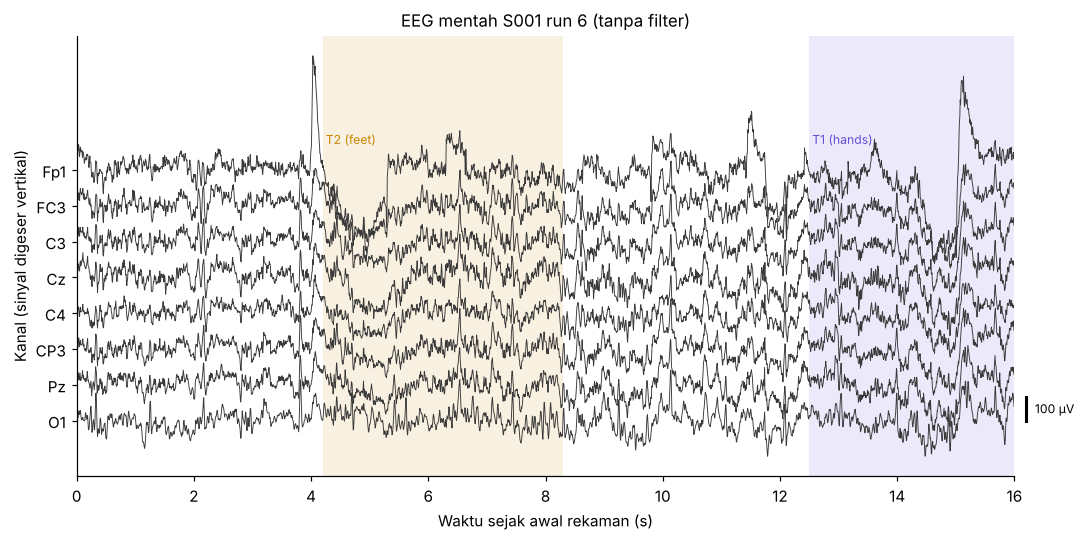

In [6]:
def plot_raw_segment(raw, channels, t_start, t_stop, title):
    picks = [raw.ch_names.index(ch) for ch in channels]
    start, stop = int(t_start * SFREQ), int(t_stop * SFREQ)
    data_uV = raw.get_data(picks=picks, start=start, stop=stop) * 1e6
    times = np.arange(start, stop) / SFREQ
    spacing = 150.0
    fig, ax = plt.subplots(figsize=(11, 5.2))
    for onset, duration, desc in zip(raw.annotations.onset, raw.annotations.duration, raw.annotations.description):
        if desc in ("T1", "T2") and onset < t_stop and onset + duration > t_start:
            name = "hands" if desc == "T1" else "feet"
            ax.axvspan(max(onset, t_start), min(onset + duration, t_stop), color=CLASS_COLORS[name], alpha=0.12, lw=0)
            ax.text(onset + 0.05, spacing * len(channels) - 40, f"{desc} ({name})", fontsize=8, color=CLASS_COLORS[name])
    for i, ch in enumerate(channels):
        offset = spacing * (len(channels) - 1 - i)
        ax.plot(times, data_uV[i] - np.median(data_uV[i]) + offset, color="#3a3a3a", lw=0.6)
    ax.set_yticks([spacing * (len(channels) - 1 - i) for i in range(len(channels))], channels)
    ax.plot([t_stop + 0.2] * 2, [0, 100], color="black", lw=2, clip_on=False)
    ax.text(t_stop + 0.35, 50, "100 µV", va="center", fontsize=8)
    ax.set_xlim(t_start, t_stop)
    ax.set_xlabel("Waktu sejak awal rekaman (s)")
    ax.set_ylabel("Kanal (sinyal digeser vertikal)")
    ax.set_title(title)
    return fig

example_subject, example_run = SUBJECTS[0], RUNS[0]
raw_channels = ["Fp1", "FC3", "C3", "Cz", "C4", "CP3", "Pz", "O1"]
fig = plot_raw_segment(raws[(example_subject, example_run)], raw_channels, 0, 16,
                       f"EEG mentah S{example_subject:03d} run {example_run} (tanpa filter)")
save_fig(fig, f"01_raw_eeg_S{example_subject:03d}_R{example_run:02d}.png")
plt.show()

**Cara membaca.** Sumbu horizontal adalah waktu; setiap garis satu kanal yang digeser ke atas agar tidak tumpang tindih (batang hitam di kanan = 100 µV). Perhatikan bahwa sinyal terlihat seperti noise acak: tidak ada "tanda" yang jelas kapan subjek membayangkan tangan atau kaki. Perubahan ERD yang kita cari hanya beberapa µV dan tersembunyi di dalam osilasi yang lebih besar. Kanal Fp1 (paling atas, dekat mata) biasanya paling rentan terhadap artefak gerak mata.

Mata manusia tidak pandai membaca frekuensi dari gelombang campuran. Untuk itu kita memakai **power spectral density (PSD)**, yang memecah sinyal menjadi kontribusi setiap frekuensi.

### Power spectral density

Untuk sinyal $x(t)$, PSD $P(f)$ menyatakan berapa daya sinyal yang berada di sekitar frekuensi $f$ (satuan µV²/Hz). Metode Welch memotong sinyal menjadi segmen-segmen pendek, menghitung transformasi Fourier tiap segmen, lalu merata-ratakan kuadrat magnitudonya:

$$
\hat P(f) = \frac{1}{K}\sum_{k=1}^{K} \frac{1}{f_s\,\sum_n w[n]^2}\left|\sum_{n} w[n]\,x_k[n]\,e^{-i2\pi f n/f_s}\right|^2 ,
$$

dengan $x_k$ segmen ke-$k$, $w[n]$ jendela (Hamming), $K$ jumlah segmen, dan $f_s=160$ Hz. Merata-ratakan $K$ segmen membuat estimasi lebih stabil. Di sini panjang segmen 2 s (320 sampel), sehingga resolusi frekuensi 0,5 Hz.

Gambar tersimpan: outputs/figures/02_psd_raw.png


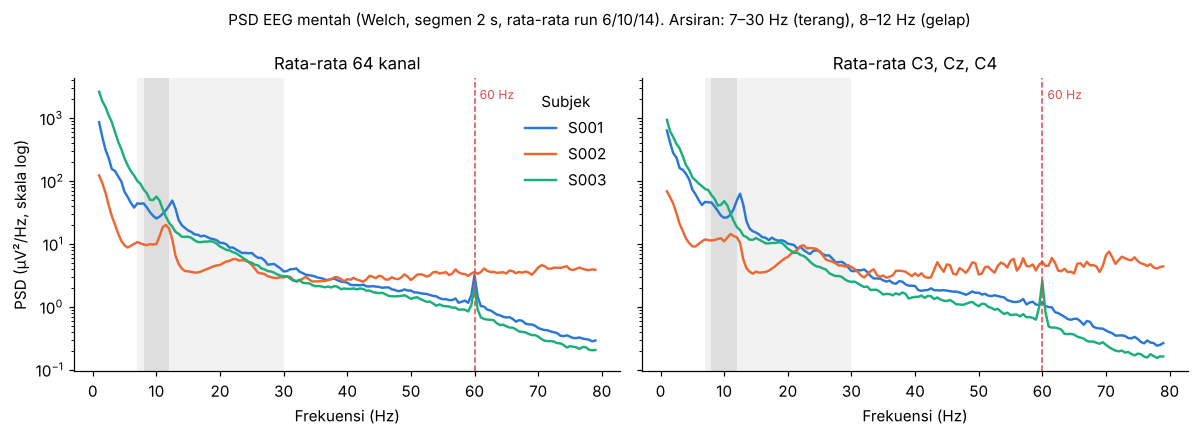

Puncak 60 Hz relatif terhadap tetangga 55–58/62–65 Hz (dB): {'S001': np.float64(4.94), 'S002': np.float64(0.08), 'S003': np.float64(4.35)}


In [7]:
psd_rows = {}
for subject in SUBJECTS:
    spectra = []
    for run in RUNS:
        psd = raws[(subject, run)].compute_psd(method="welch", fmin=1.0, fmax=79.0, n_fft=320, n_overlap=160)
        spectra.append(psd.get_data() * 1e12)   # V²/Hz -> µV²/Hz
    psd_rows[subject] = np.mean(spectra, axis=0)  # rata-rata 3 run: (64 kanal, n_freq)
psd_freqs = psd.freqs

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
subject_line_colors = ["#2a78d6", "#eb6834", "#1baf7a"]
for ax, channel_set, title in [(axes[0], None, "Rata-rata 64 kanal"), (axes[1], ["C3", "Cz", "C4"], "Rata-rata C3, Cz, C4")]:
    for color, subject in zip(subject_line_colors, SUBJECTS):
        idx = slice(None) if channel_set is None else [CH_NAMES.index(c) for c in channel_set]
        ax.semilogy(psd_freqs, psd_rows[subject][idx].mean(axis=0), color=color, lw=1.6, label=f"S{subject:03d}")
    ax.axvspan(L_FREQ, H_FREQ, color="#888888", alpha=0.10, lw=0)
    ax.axvspan(CONN_FMIN, CONN_FMAX, color="#888888", alpha=0.18, lw=0)
    ax.axvline(60, color="#e34948", ls="--", lw=1)
    ax.text(60.8, 0.93, "60 Hz", color="#e34948", fontsize=8, transform=ax.get_xaxis_transform())
    ax.set_xlabel("Frekuensi (Hz)")
    ax.set_title(title)
axes[0].set_ylabel("PSD (µV²/Hz, skala log)")
axes[0].legend(title="Subjek")
fig.suptitle("PSD EEG mentah (Welch, segmen 2 s, rata-rata run 6/10/14). Arsiran: 7–30 Hz (terang), 8–12 Hz (gelap)", fontsize=10)
fig.tight_layout()
save_fig(fig, "02_psd_raw.png")
plt.show()

line_noise = {}
for subject in SUBJECTS:
    mean_psd = psd_rows[subject].mean(axis=0)
    peak = mean_psd[(psd_freqs >= 59.5) & (psd_freqs <= 60.5)].max()
    neighbours = mean_psd[((psd_freqs >= 55) & (psd_freqs < 58)) | ((psd_freqs > 62) & (psd_freqs <= 65))].mean()
    line_noise[f"S{subject:03d}"] = round(10 * np.log10(peak / neighbours), 2)
print("Puncak 60 Hz relatif terhadap tetangga 55–58/62–65 Hz (dB):", line_noise)

**Cara membaca PSD.** Sumbu vertikal logaritmik karena daya EEG turun tajam dengan frekuensi (pola kira-kira $1/f$). Tonjolan di sekitar 8–12 Hz adalah ritme alfa/mu. Panel kanan menunjukkan rata-rata C3, Cz, dan C4, yaitu kanal di atas korteks sensorimotor. Angka "puncak 60 Hz" menunjukkan apakah ada interferensi listrik: nilai positif beberapa dB berarti ada puncak di 60 Hz.

**Mengapa EEG mentah belum siap untuk klasifikasi?**
1. Daya terbesar ada di frekuensi rendah (drift, gerak mata), bukan di pita mu/beta yang membawa informasi MI.
2. Sinyal kontinu belum dipotong per trial, sehingga belum ada pasangan "sinyal → label".
3. Artefak besar dapat mendominasi estimasi kovarians dan merusak CSP.

Interferensi 60 Hz, jika ada, berada **jauh di luar** pita 7–30 Hz yang akan kita pakai, sehingga band-pass sudah meredamnya; notch filter tambahan tidak diperlukan (PROJECT_SPEC §5.5).

Langkah berikutnya: membersihkan dan memeriksa kualitas sinyal secara terdokumentasi.

---

## 04 — Preprocessing dan quality control

> **Pertanyaan:** bagaimana membersihkan sinyal secukupnya, tanpa diam-diam membocorkan informasi antar-kanal atau antar-run, dan tanpa membuang data secara sewenang-wenang?

### Keputusan preprocessing (semuanya ditetapkan sebelum melihat skor)

| Langkah | Keputusan | Alasan |
|---|---|---|
| Referensi | **Tidak di-re-reference**; dipakai referensi rekaman asli dari file EDF | *Common average reference* mencampurkan 64 kanal ke setiap kanal, sehingga subset 8 kanal diam-diam memakai informasi 56 kanal lain (PROJECT_SPEC §5.4). Skema yang sama dipakai untuk semua subset. |
| Filter | Band-pass FIR 7–30 Hz, zero-phase, **per run** | Mencakup mu/beta dan band konektivitas 8–12 Hz. Filter tetap tidak belajar dari label, sehingga aman diterapkan per run. |
| Notch | Tidak dipakai | 60 Hz sudah di luar pita band-pass. |
| ICA | **Tidak dipakai** | Menghapus komponen ICA bernomor tetap tidak dapat dipertanggungjawabkan; ICA pada gabungan run juga berisiko membocorkan informasi run uji (PROJECT_SPEC §10 Risk 5). |
| Kanal buruk | Dideteksi dengan aturan tetap dan **dilaporkan**, tidak dibuang | Membuang kanal akan membuat subset kurang dari 8; spesifikasi meminta berhenti dan melapor, bukan mengganti kanal. |
| Penolakan epoch | Peak-to-peak > 400 µV pada salah satu dari 64 kanal | Hanya artefak kasar. Dihitung pada 64 kanal agar **set epoch sama** untuk semua subset. |

### Aturan deteksi kanal buruk

Untuk setiap run, hitung simpangan baku $\sigma_c$ setiap kanal $c$ (setelah membuang rata-rata). Kanal ditandai:
- **flat** jika $\sigma_c < 0{,}5$ µV;
- **outlier** jika *robust z-score* dari $\log \sigma_c^2$ melebihi 5:

$$
z_c = \frac{\log\sigma_c^2 - \operatorname{median}_k \log\sigma_k^2}{1{,}4826\cdot \operatorname{MAD}_k\left(\log\sigma_k^2\right)},
$$

dengan MAD = *median absolute deviation*. Faktor 1,4826 membuat MAD sebanding dengan simpangan baku untuk data normal. Median dan MAD dipakai karena tidak mudah "terseret" oleh satu kanal ekstrem, berbeda dengan rata-rata.

In [8]:
def channel_qc(raw):
    sigma_uV = raw.get_data().std(axis=1) * 1e6
    log_var = np.log(sigma_uV ** 2)
    mad = np.median(np.abs(log_var - np.median(log_var)))
    robust_z = (log_var - np.median(log_var)) / (1.4826 * mad)
    return sigma_uV, robust_z

qc_rows = []
for (subject, run), raw in raws.items():
    sigma_uV, robust_z = channel_qc(raw)
    for ch, s, z in zip(CH_NAMES, sigma_uV, robust_z):
        qc_rows.append({"subject": subject, "run": run, "channel": ch, "std_uV": round(s, 2),
                        "robust_z_logvar": round(z, 2), "flat": s < 0.5, "outlier": abs(z) > 5})
qc_channels = pd.DataFrame(qc_rows)
qc_channels.to_csv(OUT_DIR / "qc_channels.csv", index=False)

flagged = qc_channels[qc_channels.flat | qc_channels.outlier]
print("Kanal yang ditandai (flat atau |z| > 5):", "tidak ada" if flagged.empty else "")
if not flagged.empty:
    display(flagged)
top_z = (qc_channels.assign(abs_z=qc_channels.robust_z_logvar.abs())
         .sort_values("abs_z", ascending=False).groupby("subject").head(3)
         [["subject", "run", "channel", "std_uV", "robust_z_logvar"]])
print("Tiga kanal dengan |z| terbesar per subjek (untuk transparansi):")
display(top_z)

Kanal yang ditandai (flat atau |z| > 5): 


,subject,run,channel,std_uV,robust_z_logvar,flat,outlier
405,3,6,Fp1,203.48,5.30,False,True
407,3,6,Fp2,203.18,5.29,False,True
408,3,6,AF7,199.29,5.20,False,True


Tiga kanal dengan |z| terbesar per subjek (untuk transparansi):


,subject,run,channel,std_uV,robust_z_logvar
405,3,6,Fp1,203.48,5.30
407,3,6,Fp2,203.18,5.29
408,3,6,AF7,199.29,5.20
107,1,10,T10,25.62,-4.85
149,1,14,Fp1,96.22,4.74
85,1,10,Fp1,100.75,4.68
296,2,10,T7,38.37,4.05
301,2,10,TP8,12.00,-3.93
365,2,14,TP8,11.70,-3.56


**Interpretasi.** Tabel kedua selalu ditampilkan, bahkan jika tidak ada kanal yang melewati ambang, supaya pembaca dapat melihat kanal mana yang paling "menyimpang". Kanal frontal (Fp1, Fp2, AF7) atau oksipital (O1, O2, Iz) biasanya muncul di sini: frontal karena dekat mata, oksipital karena ritme alfa yang kuat. Variabilitas seperti itu bukan otomatis "rusak". Jika ada kanal yang ditandai dan termasuk dalam kandidat subset, hal itu dicatat sebagai keterbatasan, bukan diganti diam-diam.

### Filter band-pass 7–30 Hz

Filter FIR (*finite impulse response*) menghitung setiap sampel keluaran sebagai jumlah berbobot sampel masukan di sekitarnya:

$$
y[n] = \sum_{k=-M}^{M} h[k]\,x[n-k],
$$

dengan $h[k]$ koefisien filter yang dirancang agar meloloskan 7–30 Hz dan meredam sisanya. *Zero-phase* berarti filter tidak menggeser waktu sinyal, penting karena kita akan menganalisis **fase**. Filter diterapkan **per run**, sehingga tepi satu run tidak bocor ke run lain.

Gambar tersimpan: outputs/figures/01b_filtered_eeg_S001_R06.png


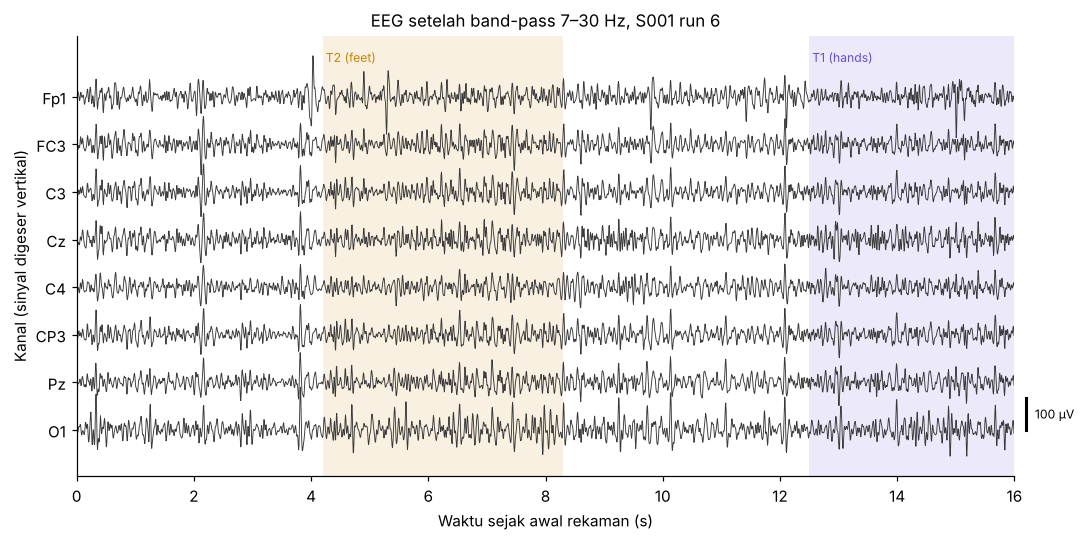

In [9]:
filtered = {}
for key, raw in raws.items():
    filtered[key] = raw.copy().filter(l_freq=L_FREQ, h_freq=H_FREQ, method="fir", fir_design="firwin",
                                      phase="zero", skip_by_annotation="edge")
example = filtered[(example_subject, example_run)]
fig = plot_raw_segment(example, raw_channels, 0, 16,
                       f"EEG setelah band-pass {L_FREQ:.0f}–{H_FREQ:.0f} Hz, S{example_subject:03d} run {example_run}")
save_fig(fig, f"01b_filtered_eeg_S{example_subject:03d}_R{example_run:02d}.png")
plt.show()

Dibanding gambar mentah, drift lambat dan fluktuasi besar sudah hilang; yang tersisa adalah osilasi 7–30 Hz. Amplitudo kini lebih sebanding antar-kanal.

### Menentukan ambang penolakan epoch secara transparan

Ambang peak-to-peak (PTP) yang lazim di literatur adalah 100–150 µV. Sebelum menetapkannya, kita memeriksa **distribusi amplitudo** setiap epoch kandidat (tanpa melihat label kelas dan tanpa skor model apa pun). Untuk setiap epoch, dihitung PTP maksimum di antara 64 kanal:

$$
\mathrm{PTP}_e = \max_c \left(\max_t x_{e,c}(t) - \min_t x_{e,c}(t)\right).
$$

Persentase epoch yang AKAN ditolak pada berbagai ambang (64 kanal, data 7–30 Hz):


,>100 µV,>150 µV,>200 µV,>300 µV,>400 µV,>500 µV
subject,,,,,,
S001,100%,98%,42%,7%,2%,2%
S002,53%,13%,4%,0%,0%,0%
S003,100%,100%,89%,22%,0%,0%


Gambar tersimpan: outputs/figures/03_qc_epoch_ptp_distribution.png


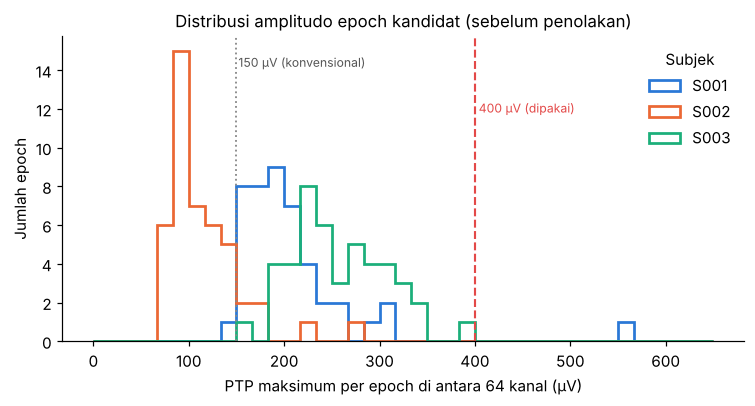

In [10]:
def candidate_epochs(raw_filtered, subject, run, reject=None):
    events, _ = mne.events_from_annotations(raw_filtered, event_id={"T1": 1, "T2": 2})
    epochs = mne.Epochs(raw_filtered, events, event_id=EVENT_ID, tmin=TMIN, tmax=TMAX,
                        baseline=None, preload=True, reject=None, reject_by_annotation=True)
    epochs.metadata = pd.DataFrame({
        "subject": subject, "run": run, "trial_in_run": np.arange(len(epochs)),
        "label": [LABEL_NAMES[c - 1] for c in epochs.events[:, 2]],
        "onset_s": (epochs.events[:, 0] - raw_filtered.first_samp) / SFREQ,
    })
    return epochs

ptp_rows = []
for (subject, run), raw_f in filtered.items():
    ep = candidate_epochs(raw_f, subject, run)
    ptp_uV = np.ptp(ep.get_data(), axis=2).max(axis=1) * 1e6
    for value in ptp_uV:
        ptp_rows.append({"subject": f"S{subject:03d}", "run": run, "max_ptp_uV": value})
ptp_table = pd.DataFrame(ptp_rows)

thresholds = [100, 150, 200, 300, 400, 500]
share = pd.DataFrame({f">{t} µV": ptp_table.groupby("subject").max_ptp_uV.apply(lambda v: f"{np.mean(v > t):.0%}")
                      for t in thresholds})
print("Persentase epoch yang AKAN ditolak pada berbagai ambang (64 kanal, data 7–30 Hz):")
display(share)

fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(0, max(650, ptp_table.max_ptp_uV.max() + 20), 40)
for color, (subject, grp) in zip(subject_line_colors, ptp_table.groupby("subject")):
    ax.hist(grp.max_ptp_uV, bins=bins, histtype="step", lw=1.8, color=color, label=subject)
ax.axvline(150, color="#888888", ls=":", lw=1.2); ax.text(152, ax.get_ylim()[1] * 0.9, "150 µV (konvensional)", fontsize=8, color="#555555")
ax.axvline(REJECT_PTP_UV, color="#e34948", ls="--", lw=1.4); ax.text(REJECT_PTP_UV + 4, ax.get_ylim()[1] * 0.75, f"{REJECT_PTP_UV:.0f} µV (dipakai)", fontsize=8, color="#e34948")
ax.set_xlabel("PTP maksimum per epoch di antara 64 kanal (µV)")
ax.set_ylabel("Jumlah epoch")
ax.set_title("Distribusi amplitudo epoch kandidat (sebelum penolakan)")
ax.legend(title="Subjek")
save_fig(fig, "03_qc_epoch_ptp_distribution.png")
plt.show()

**Interpretasi dan keputusan.** Pada data ini, ambang konvensional 150 µV akan menolak hampir semua epoch pada sebagian subjek (lihat tabel): EEGBCI memiliki amplitudo alfa/mu yang besar, terutama di kanal oksipital dan frontal, sehingga ambang itu tidak cocok. Kehilangan hampir semua trial pada satu subjek akan membuat validasi per run mustahil. **Keputusan:** ambang ditetapkan 400 µV untuk menolak hanya artefak kasar. Keputusan ini diambil setelah melihat distribusi amplitudo, **tetapi sebelum melihat label, skor klasifikasi, atau konektivitas**, dan aturan yang sama dipakai untuk semua subjek, run, dan subset. Keputusan ini adalah penyimpangan terdokumentasi dari kebiasaan umum, bukan dari spesifikasi (spesifikasi meminta ambang tetap yang dicatat).

Data sudah bersih secukupnya. Sekarang sinyal kontinu harus dipotong menjadi trial berlabel.

---

## 05 — Epoching dan label

> **Pertanyaan:** bagian mana dari rekaman yang benar-benar mewakili "membayangkan tangan" atau "membayangkan kaki"?

### Mengapa epoch?

Classifier membutuhkan pasangan (contoh, label). Rekaman kontinu 125 detik bukan satu contoh, melainkan rangkaian banyak periode tugas dan istirahat. **Epoching** memotong sinyal pada jendela waktu tetap relatif terhadap onset setiap cue. Setiap epoch menjadi matriks

$$
X_e \in \mathbb{R}^{C\times T}, \qquad C = 64 \text{ kanal},\quad T = (t_{\max}-t_{\min})\,f_s + 1 = (2{,}5-1{,}0)\cdot 160 + 1 = 241 \text{ sampel}.
$$

### Mengapa 1,0–2,5 s setelah onset?

Satu detik pertama setelah cue berisi respons visual terhadap cue dan waktu reaksi; ERD akibat imajinasi biasanya lebih stabil setelahnya. Jendela berakhir di 2,5 s, jauh sebelum cue berakhir (±4,1 s). Jendela ini mengikuti contoh resmi MNE dan ditetapkan di PROJECT_SPEC §5.6 **sebelum** melihat skor. `baseline=None` karena koreksi baseline tidak bermakna untuk sinyal yang sudah difilter band-pass dan bisa memasukkan informasi dari periode lain.

In [11]:
epochs_by_run, epoch_rows = {}, []
for (subject, run), raw_f in filtered.items():
    ep = candidate_epochs(raw_f, subject, run)
    n_before = len(ep)
    ep.drop_bad(reject=dict(eeg=REJECT_PTP_UV * 1e-6))
    epochs_by_run[(subject, run)] = ep
    epoch_rows.append({"subject": f"S{subject:03d}", "run": run, "n_cues": n_before,
                       "n_rejected": n_before - len(ep), "n_kept": len(ep),
                       "n_hands": int(np.sum(ep.metadata.label == "hands")),
                       "n_feet": int(np.sum(ep.metadata.label == "feet"))})
epoch_table = pd.DataFrame(epoch_rows)
epoch_table.to_csv(OUT_DIR / "qc_epochs.csv", index=False)
display(epoch_table)

# Gabungkan per subjek, simpan label dan run untuk setiap epoch
data = {}
for subject in SUBJECTS:
    eps = [epochs_by_run[(subject, run)] for run in RUNS]
    X = np.concatenate([e.get_data() for e in eps])                  # (n_epoch, 64, 241), volt
    meta = pd.concat([e.metadata for e in eps], ignore_index=True)
    y = (meta.label == "feet").astype(int).to_numpy()                # 0 = hands, 1 = feet
    run_of_epoch = meta.run.to_numpy()
    data[subject] = {"X": X, "y": y, "run": run_of_epoch, "meta": meta}

# Validasi bentuk, label, dan identitas run (AT-05)
for subject, d in data.items():
    assert d["X"].shape[1:] == (64, 241), d["X"].shape
    assert len(d["X"]) == len(d["y"]) == len(d["run"])
    assert set(np.unique(d["y"])) == {0, 1}
    for run in RUNS:
        y_run = d["y"][d["run"] == run]
        assert set(np.unique(y_run)) == {0, 1}, f"S{subject:03d} run {run} tidak memuat dua kelas"
    print(f"S{subject:03d}: X {d['X'].shape}, hands = {np.sum(d['y'] == 0)}, feet = {np.sum(d['y'] == 1)}")

,subject,run,n_cues,n_rejected,n_kept,n_hands,n_feet
0,S001,6,15,1,14,6,8
1,S001,10,15,0,15,7,8
2,S001,14,15,0,15,7,8
3,S002,6,15,0,15,8,7
4,S002,10,15,0,15,8,7
5,S002,14,15,0,15,8,7
6,S003,6,15,0,15,7,8
7,S003,10,15,0,15,7,8
8,S003,14,15,0,15,7,8


S001: X (44, 64, 241), hands = 20, feet = 24
S002: X (45, 64, 241), hands = 24, feet = 21
S003: X (45, 64, 241), hands = 21, feet = 24


**Membaca tabel.** `n_cues` adalah jumlah cue T1+T2 per run; `n_rejected` epoch yang ditolak oleh aturan 400 µV. Kolom `n_hands` dan `n_feet` menunjukkan keseimbangan kelas per run. Setiap run harus memuat kedua kelas karena setiap run akan bergantian menjadi data uji. Bentuk `X` = (jumlah epoch, 64 kanal, 241 sampel).

Dua gambar berikut menunjukkan **di mana** epoch diambil pada garis waktu rekaman dan seperti apa satu epoch.

Gambar tersimpan: outputs/figures/04_event_timeline_S001.png


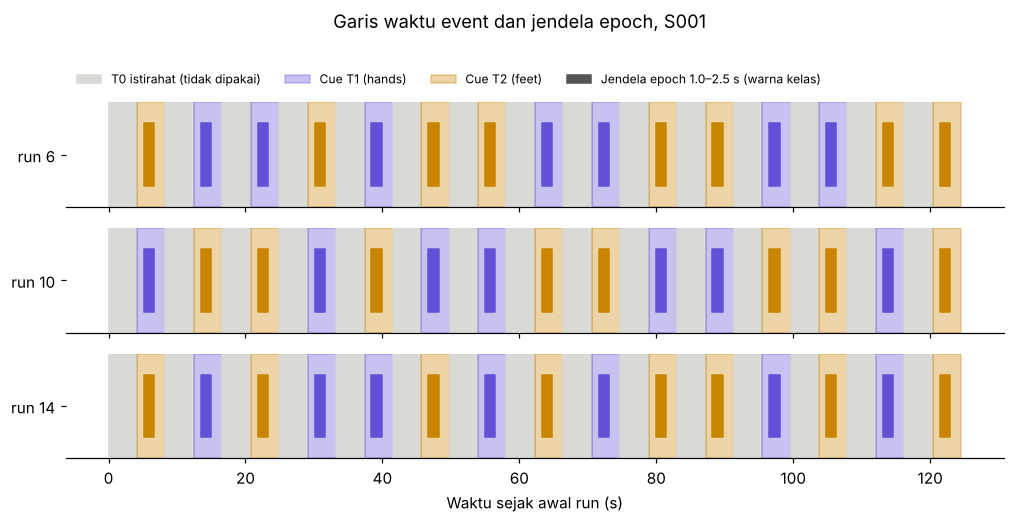

Gambar tersimpan: outputs/figures/05_representative_epochs_S001.png


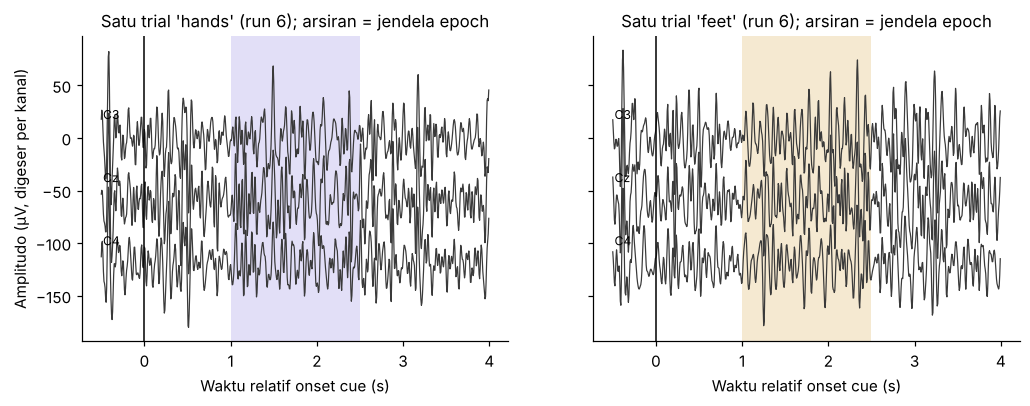

In [12]:
fig, axes = plt.subplots(len(RUNS), 1, figsize=(11, 4.2), sharex=True)
for ax, run in zip(axes, RUNS):
    raw = raws[(example_subject, run)]
    for onset, duration, desc in zip(raw.annotations.onset, raw.annotations.duration, raw.annotations.description):
        if desc == "T0":
            ax.broken_barh([(onset, duration)], (0, 1), color="#d9d9d6")
        else:
            name = "hands" if desc == "T1" else "feet"
            ax.broken_barh([(onset, duration)], (0, 1), color=CLASS_COLORS[name], alpha=0.35)
            ax.broken_barh([(onset + TMIN, TMAX - TMIN)], (0.2, 0.6), color=CLASS_COLORS[name])
    ax.set_yticks([0.5], [f"run {run}"])
    ax.set_ylim(0, 1)
    ax.spines["left"].set_visible(False)
axes[-1].set_xlabel("Waktu sejak awal run (s)")
legend_items = [Patch(color="#d9d9d6", label="T0 istirahat (tidak dipakai)"),
                Patch(color=CLASS_COLORS["hands"], alpha=0.35, label="Cue T1 (hands)"),
                Patch(color=CLASS_COLORS["feet"], alpha=0.35, label="Cue T2 (feet)"),
                Patch(color="#555555", label=f"Jendela epoch {TMIN}–{TMAX} s (warna kelas)")]
axes[0].legend(handles=legend_items, ncol=4, loc="lower left", bbox_to_anchor=(0, 1.05), fontsize=8)
fig.suptitle(f"Garis waktu event dan jendela epoch, S{example_subject:03d}", y=1.08)
save_fig(fig, f"04_event_timeline_S{example_subject:03d}.png")
plt.show()

# Satu epoch per kelas pada C3, Cz, C4, beserta posisinya relatif terhadap onset
ep = epochs_by_run[(example_subject, example_run)]
raw_f = filtered[(example_subject, example_run)]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, label in zip(axes, LABEL_NAMES):
    first = ep.metadata.index[ep.metadata.label == label][0]
    onset = ep.metadata.loc[first, "onset_s"]
    start, stop = int((onset - 0.5) * SFREQ), int((onset + 4.0) * SFREQ)
    t = np.arange(start, stop) / SFREQ - onset
    for i, ch in enumerate(["C3", "Cz", "C4"]):
        trace = raw_f.get_data(picks=[ch], start=start, stop=stop)[0] * 1e6
        ax.plot(t, trace - 60 * i, lw=0.8, color="#3a3a3a")
        ax.text(-0.48, -60 * i + 18, ch, fontsize=8)
    ax.axvspan(TMIN, TMAX, color=CLASS_COLORS[label], alpha=0.18, lw=0)
    ax.axvline(0, color="black", lw=1)
    ax.set_title(f"Satu trial '{label}' (run {example_run}); arsiran = jendela epoch")
    ax.set_xlabel("Waktu relatif onset cue (s)")
axes[0].set_ylabel("Amplitudo (µV, digeser per kanal)")
save_fig(fig, f"05_representative_epochs_S{example_subject:03d}.png")
plt.show()

**Interpretasi.** Garis waktu memperlihatkan pola eksperimen: cue imajinasi (T1/T2) diselingi istirahat (T0), dan hanya potongan 1,0–2,5 s dari setiap cue yang dipakai. Pada contoh trial tunggal, tidak tampak perbedaan mencolok antara hands dan feet. Ini wajar: perbedaan ERD bersifat statistik (terlihat dari varians banyak trial), bukan bentuk gelombang yang dapat dikenali per trial. Inilah alasan kita membutuhkan CSP pada bagian 07.

Sebelum masuk ke CSP, kita harus menetapkan **dari kanal mana** sinyal akan diambil.

---

## 06 — Kandidat seleksi kanal EEG

> **Pertanyaan:** dari 64 kanal, delapan kanal mana yang layak dicoba, dan mengapa ruang pencariannya dibatasi?

### Mengapa lokasi kanal penting

Karena volume conduction, setiap elektroda paling peka terhadap sumber di bawahnya, tetapi juga menangkap sumber yang lebih jauh. Kanal di atas korteks sensorimotor (baris FC, C, CP) diharapkan paling informatif untuk MI. Kanal frontal dan oksipital lebih banyak menangkap aktivitas lain (mata, visual).

### Mengapa hanya 10 kandidat?

Banyaknya cara memilih 8 dari 64 kanal adalah $\binom{64}{8} \approx 4{,}4\times10^{9}$. Mencoba semuanya dengan ±30 trial latih hampir pasti menghasilkan *winner's curse*: subset yang "menang" karena kebetulan cocok dengan noise. Karena itu PROJECT_SPEC §6 menetapkan **10 kandidat sebelum melihat data**, mulai dari sensorimotor klasik (S01) hingga pembanding non-sentral (S10). Kandidat tidak diubah karena hasil.

### Subset anatomis vs subset terpilih-data

- **S01 (ANATOMICAL)** dipilih dari pengetahuan anatomi, *sebelum* model belajar apa pun. Ia baseline yang tidak pernah "melihat" data.
- **S_CLS** dan **S_CONN** dipilih dari 10 kandidat berdasarkan **data latih**, masing-masing dengan kriteria berbeda. Mereka bisa saja sama dengan S01.

In [13]:
CANDIDATES = {
    "S01": ["FC3", "FC4", "C3", "Cz", "C4", "CP3", "CPz", "CP4"],   # anatomical baseline sensorimotor
    "S02": ["F3", "F4", "FC3", "FC4", "C3", "Cz", "C4", "Pz"],      # frontal-central
    "S03": ["C3", "Cz", "C4", "CP3", "CP4", "P3", "Pz", "P4"],      # central-parietal
    "S04": ["FC1", "FC2", "FC3", "FC4", "C1", "C2", "C3", "C4"],    # frontocentral
    "S05": ["C1", "C2", "C3", "Cz", "C4", "C5", "C6", "CPz"],       # broad central
    "S06": ["F3", "Fz", "F4", "FC1", "FC2", "FC3", "FC4", "Cz"],    # frontal
    "S07": ["CP1", "CP2", "CP3", "CP4", "P3", "Pz", "P4", "Cz"],    # posterior sensorimotor
    "S08": ["FC3", "C3", "CP3", "P3", "FC4", "C4", "CP4", "P4"],    # bilateral
    "S09": ["F3", "F4", "C3", "C4", "P3", "P4", "O1", "O2"],        # spatially distributed control
    "S10": ["Fp1", "Fp2", "F7", "F8", "P7", "P8", "O1", "O2"],      # noncentral comparator
}
CANDIDATE_CONCEPT = {"S01": "anatomical baseline", "S02": "frontal-central", "S03": "central-parietal",
                     "S04": "frontocentral", "S05": "broad central", "S06": "frontal",
                     "S07": "posterior sensorimotor", "S08": "bilateral", "S09": "distributed control",
                     "S10": "noncentral comparator"}
ANATOMICAL_ID = "S01"

# AT-04: setiap kandidat harus 8 kanal unik dan ada di EDF. Jika gagal: BERHENTI, jangan ganti kanal.
for sid, chans in CANDIDATES.items():
    assert len(chans) == 8 and len(set(chans)) == 8, f"{sid} tidak berisi 8 kanal unik"
    missing = set(chans) - set(CH_NAMES)
    assert not missing, f"{sid}: kanal tidak ditemukan di EDF: {missing}"
CANDIDATE_IDX = {sid: [CH_NAMES.index(ch) for ch in chans] for sid, chans in CANDIDATES.items()}

flag_lookup = set(zip(flagged.subject, flagged.channel)) if not flagged.empty else set()
candidate_table = pd.DataFrame([{
    "subset_id": sid, "concept": CANDIDATE_CONCEPT[sid], "channels": ", ".join(chans),
    "all_in_EDF": True,
    "QC_flagged_channels": ", ".join(sorted({f"S{s:03d}:{c}" for (s, c) in flag_lookup if c in chans})) or "-",
} for sid, chans in CANDIDATES.items()])
display(candidate_table)
print("Kanal unik yang dipakai oleh setidaknya satu kandidat:", len({c for v in CANDIDATES.values() for c in v}))

,subset_id,concept,channels,all_in_EDF,QC_flagged_channels
0,S01,anatomical baseline,"FC3, FC4, C3, Cz, C4, CP3, CPz, CP4",True,-
1,S02,frontal-central,"F3, F4, FC3, FC4, C3, Cz, C4, Pz",True,-
2,S03,central-parietal,"C3, Cz, C4, CP3, CP4, P3, Pz, P4",True,-
3,S04,frontocentral,"FC1, FC2, FC3, FC4, C1, C2, C3, C4",True,-
4,S05,broad central,"C1, C2, C3, Cz, C4, C5, C6, CPz",True,-
5,S06,frontal,"F3, Fz, F4, FC1, FC2, FC3, FC4, Cz",True,-
6,S07,posterior sensorimotor,"CP1, CP2, CP3, CP4, P3, Pz, P4, Cz",True,-
7,S08,bilateral,"FC3, C3, CP3, P3, FC4, C4, CP4, P4",True,-
8,S09,distributed control,"F3, F4, C3, C4, P3, P4, O1, O2",True,-
9,S10,noncentral comparator,"Fp1, Fp2, F7, F8, P7, P8, O1, O2",True,"S003:Fp1, S003:Fp2"


Kanal unik yang dipakai oleh setidaknya satu kandidat: 30


Semua sepuluh kandidat valid terhadap nama kanal aktual di EDF (AT-04). Gambar berikut memetakan setiap kandidat pada kepala yang dilihat dari atas (hidung di atas). Proyeksi 2D dihitung dari posisi 3D montage: titik-titik di garis lingkaran berada kira-kira setinggi telinga.

Gambar tersimpan: outputs/figures/06_candidate_subsets_sensor_map.png


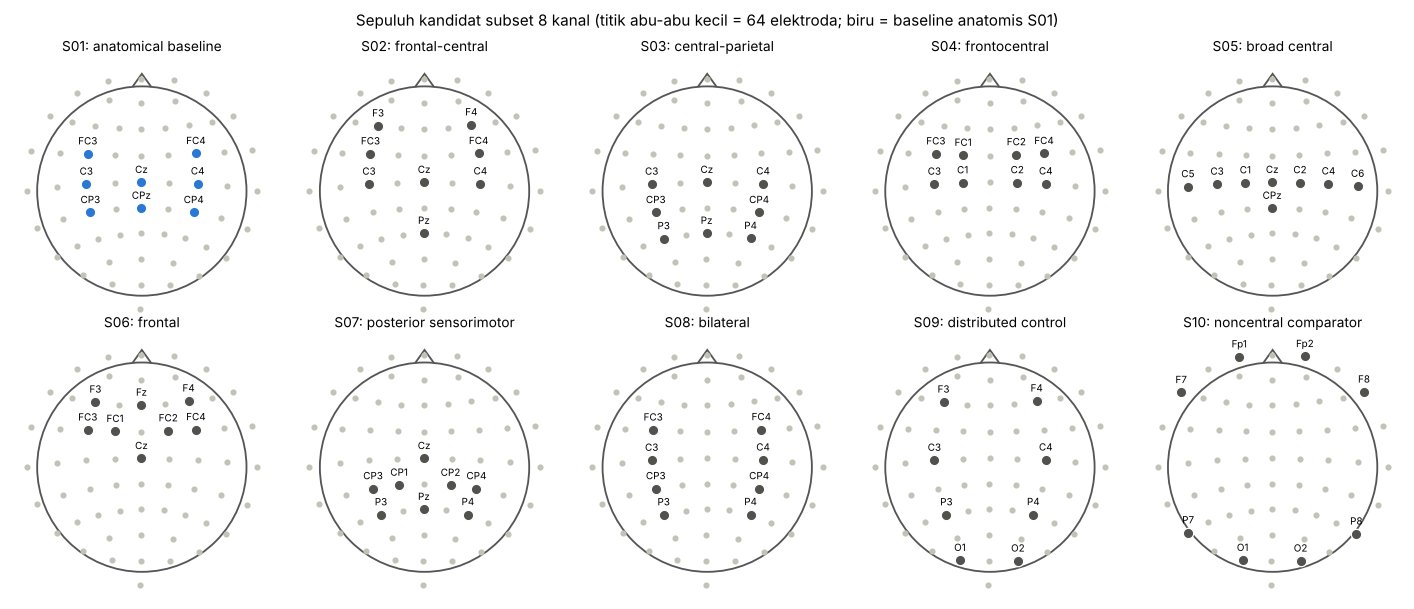

In [14]:
def sensor_xy(info):
    # Proyeksi azimutal-ekuidistan posisi 3D elektroda ke bidang 2D (hidung ke atas)
    radius, origin, _ = mne.bem.fit_sphere_to_headshape(info, dig_kinds=("eeg",), units="m")
    pos = np.array([info["chs"][i]["loc"][:3] for i in range(len(info["ch_names"]))]) - origin
    pos /= np.linalg.norm(pos, axis=1, keepdims=True)
    theta = np.arccos(np.clip(pos[:, 2], -1, 1))          # sudut dari puncak kepala
    phi = np.arctan2(pos[:, 1], pos[:, 0])
    return np.column_stack([theta * np.cos(phi), theta * np.sin(phi)]) / (np.pi / 2)

XY = sensor_xy(raws[(SUBJECTS[0], RUNS[0])].info)

def draw_head(ax):
    ax.add_patch(Circle((0, 0), 1.0, fill=False, lw=1.2, color="#555555"))
    ax.add_patch(Polygon([[-0.09, 0.995], [0, 1.12], [0.09, 0.995]], closed=False, fill=False, lw=1.2, color="#555555"))
    ax.set_xlim(-1.25, 1.25); ax.set_ylim(-1.25, 1.25); ax.set_aspect("equal"); ax.axis("off")

def draw_subset(ax, highlight, color, title, label_names=True):
    draw_head(ax)
    ax.scatter(XY[:, 0], XY[:, 1], s=9, color="#c3c2b7", zorder=2)
    idx = [CH_NAMES.index(c) for c in highlight]
    ax.scatter(XY[idx, 0], XY[idx, 1], s=46, color=color, edgecolor="white", lw=0.8, zorder=3)
    if label_names:
        for i in idx:
            ax.text(XY[i, 0], XY[i, 1] + 0.09, CH_NAMES[i], ha="center", fontsize=6.5, zorder=4)
    ax.set_title(title, fontsize=9)

fig, axes = plt.subplots(2, 5, figsize=(13, 5.6))
for ax, (sid, chans) in zip(axes.ravel(), CANDIDATES.items()):
    color = APPROACH_COLORS["ANATOMICAL"] if sid == ANATOMICAL_ID else "#52514e"
    draw_subset(ax, chans, color, f"{sid}: {CANDIDATE_CONCEPT[sid]}")
fig.suptitle("Sepuluh kandidat subset 8 kanal (titik abu-abu kecil = 64 elektroda; biru = baseline anatomis S01)", fontsize=10)
fig.tight_layout()
save_fig(fig, "06_candidate_subsets_sensor_map.png")
plt.show()

**Interpretasi.** S01–S08 berpusat di sekitar strip sensorimotor dengan variasi ke depan (S02, S04, S06) atau ke belakang (S03, S07). S09 tersebar merata, dan S10 sengaja menghindari area sentral (frontal-polar, temporal-parietal, oksipital). Banyak kandidat **saling tumpang tindih** (misalnya C3 dan C4 muncul di 8 dari 10 kandidat). Ini penting saat membaca Jaccard nanti: dua subset berbeda bisa tetap berbagi banyak kanal.

S10 **tidak** dianggap "tanpa sinyal motorik": karena volume conduction, kanal mana pun dapat menangkap sebagian aktivitas sensorimotor.

Kandidat sudah ditetapkan. Sekarang kita butuh cara mengukur **seberapa baik** sebuah subset untuk klasifikasi.

---

## 07 — Klasifikasi dengan CSP dan LDA

> **Pertanyaan:** jika perbedaan hands vs feet tidak terlihat pada satu trial, bagaimana sebuah algoritma bisa menemukannya?

### Intuisi: varians sebagai "kekerasan suara"

Ingat bahwa ERD adalah **penurunan daya** osilasi. Untuk sinyal yang sudah difilter band-pass dan berpusat di nol, daya sama dengan **varians**. Jadi pertanyaan "apakah ada ERD di C3?" sama dengan "apakah varians C3 lebih kecil saat membayangkan tangan dibanding kaki?"

Masalahnya, ERD dari satu sumber otak tersebar ke beberapa elektroda (volume conduction). **Spatial filter** adalah kombinasi linear kanal, $s(t) = \sum_c w_c\,x_c(t) = w^\top x(t)$, seperti mengatur mixer audio: menaikkan beberapa mikrofon, menurunkan yang lain, supaya satu "suara" terdengar paling jelas. CSP (*Common Spatial Patterns*) mencari bobot $w$ yang membuat varians sinyal hasil filter **sebesar mungkin untuk satu kelas dan sekecil mungkin untuk kelas lain** [blankertz2008].

### Matematika CSP

Untuk satu epoch $X_i \in \mathbb{R}^{C\times T}$ (di sini $C=8$ kanal subset, $T=241$ sampel), kovarians sampel adalah

$$
\Sigma_i = \frac{1}{T-1} X_i X_i^\top \in \mathbb{R}^{C\times C}.
$$

Elemen diagonal $\Sigma_i[c,c]$ adalah varians kanal $c$; elemen di luar diagonal adalah kovarians antar-kanal. Rata-ratakan per kelas: $C_1 = \overline{\Sigma}_{\text{hands}}$ dan $C_2 = \overline{\Sigma}_{\text{feet}}$. Varians sinyal hasil filter $w$ untuk kelas $k$ adalah $w^\top C_k w$. CSP memaksimalkan rasio

$$
J(w)=\frac{w^\top C_1 w}{w^\top (C_1+C_2)\,w}.
$$

Rasio ini berada di antara 0 dan 1. Nilai mendekati 1 berarti hampir semua varians filter berasal dari kelas 1; mendekati 0 berarti dari kelas 2. Menurunkan $J$ terhadap $w$ dan menyamakannya dengan nol menghasilkan **masalah eigen tergeneralisasi**

$$
C_1 w = \lambda\,(C_1+C_2)\,w,
$$

dengan $\lambda = J(w)$. Ada $C=8$ pasangan $(\lambda_j, w_j)$. Filter dengan $\lambda$ paling dekat ke 1 dan paling dekat ke 0 adalah yang paling diskriminatif. Kita ambil **4 filter**: dua dari setiap ujung (`component_order="alternate"`, sesuai uraian buku teks).

### Fitur log-variance

Setiap epoch diproyeksikan ke 4 filter, lalu dihitung

$$
f_j = \log\left(\frac{1}{T}\sum_{t} \big(w_j^\top x(t)\big)^2\right), \qquad j=1,\dots,4.
$$

Logaritma membuat distribusi daya (yang miring ke kanan) lebih mendekati normal, cocok untuk LDA. Satu epoch 8×241 kini diringkas menjadi **4 angka**.

### LDA sebagai aturan keputusan

*Linear Discriminant Analysis* mengasumsikan fitur setiap kelas berdistribusi normal dengan kovarians sama $\Sigma_f$. Aturan keputusannya adalah garis (atau bidang) pemisah:

$$
\hat y = \begin{cases}\text{feet} & \text{jika } a^\top f + b > 0\\ \text{hands} & \text{lainnya}\end{cases},
\qquad a = \Sigma_f^{-1}(\mu_{\text{feet}}-\mu_{\text{hands}}),\quad b = -\tfrac12 a^\top(\mu_{\text{feet}}+\mu_{\text{hands}}) + \log\frac{\pi_{\text{feet}}}{\pi_{\text{hands}}}.
$$

$\mu_k$ rata-rata fitur kelas $k$ dan $\pi_k$ proporsi kelas di data latih. Analogi: LDA menarik garis tengah antara dua "awan" titik, dengan memperhitungkan bentuk awannya.

### Balanced accuracy dan confusion matrix

Dengan TP = feet diprediksi feet, FN = feet diprediksi hands, TN = hands diprediksi hands, FP = hands diprediksi feet:

$$
BA = \frac12\left(\frac{TP}{TP+FN} + \frac{TN}{TN+FP}\right).
$$

BA adalah rata-rata *recall* kedua kelas, sehingga tidak tertipu jika satu kelas lebih banyak. Untuk dua kelas, menebak acak menghasilkan BA ≈ 0,5. Dengan hanya ±15 trial uji per run, satu trial salah mengubah BA sekitar 0,07, jadi BA per fold sangat "berbutir kasar".

### Demonstrasi pada satu fold

Kita latih CSP–LDA pada S01, run latih 6+10, lalu uji pada run 14 dari subjek pertama. Ini hanya ilustrasi; evaluasi sebenarnya ada di bagian 09–10.

Bentuk satu epoch subset: (8, 241) | fitur CSP per epoch: 4
Balanced accuracy demo (S001, latih 6+10, uji 14, S01): 1.000


Gambar tersimpan: outputs/figures/07_csp_demo_S001.png


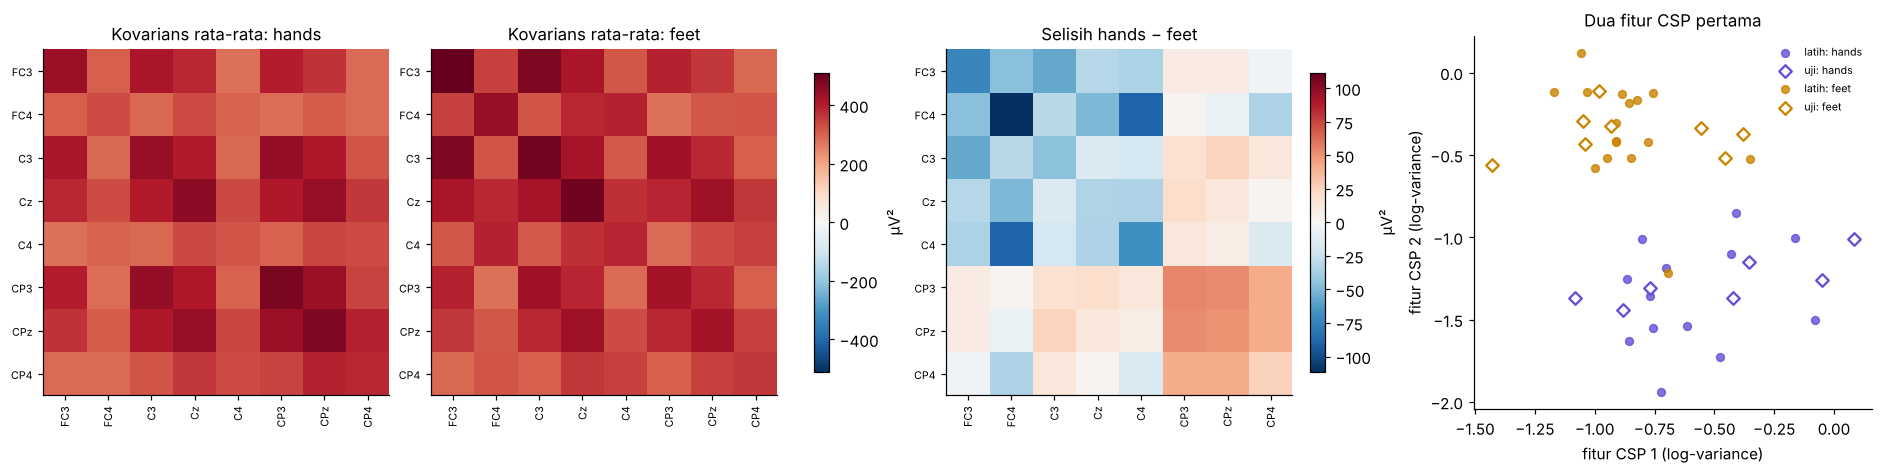

,prediksi: hands,prediksi: feet
benar: hands,7,0
benar: feet,0,8


In [15]:
def make_csp_lda():
    return Pipeline([
        ("csp", CSP(n_components=CSP_N_COMPONENTS, reg=None, log=True, norm_trace=False,
                    component_order="alternate")),
        ("lda", LinearDiscriminantAnalysis()),
    ])

def fit_and_score(X_train, y_train, X_test, y_test):
    # CSP dan LDA di-fit HANYA pada data latih yang diberikan; data uji hanya diprediksi.
    model = make_csp_lda().fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return balanced_accuracy_score(y_test, y_pred), y_pred, model

demo = data[example_subject]
idx_s01 = CANDIDATE_IDX[ANATOMICAL_ID]
demo_train = np.isin(demo["run"], [6, 10]); demo_test = demo["run"] == 14
X_demo_tr = demo["X"][demo_train][:, idx_s01]; y_demo_tr = demo["y"][demo_train]
X_demo_te = demo["X"][demo_test][:, idx_s01];  y_demo_te = demo["y"][demo_test]

# Kovarians rata-rata per kelas (µV²), hanya dari data latih
cov = {k: np.mean([x @ x.T / (x.shape[1] - 1) for x in X_demo_tr[y_demo_tr == k] * 1e6], axis=0) for k in (0, 1)}
ba_demo, y_pred_demo, model_demo = fit_and_score(X_demo_tr, y_demo_tr, X_demo_te, y_demo_te)
f_tr = model_demo.named_steps["csp"].transform(X_demo_tr)
f_te = model_demo.named_steps["csp"].transform(X_demo_te)
print("Bentuk satu epoch subset:", X_demo_tr.shape[1:], "| fitur CSP per epoch:", f_tr.shape[1])
print(f"Balanced accuracy demo (S{example_subject:03d}, latih 6+10, uji 14, S01): {ba_demo:.3f}")

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1, 1, 1, 1.15]}, layout="constrained")
vmax = max(np.abs(cov[0]).max(), np.abs(cov[1]).max())
names = CANDIDATES[ANATOMICAL_ID]
for ax, k in zip(axes[:2], (0, 1)):
    im = ax.imshow(cov[k], cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_xticks(range(8), names, rotation=90, fontsize=7); ax.set_yticks(range(8), names, fontsize=7)
    ax.set_title(f"Kovarians rata-rata: {LABEL_NAMES[k]}")
fig.colorbar(im, ax=axes[:2], shrink=0.8, label="µV²")
diff = cov[0] - cov[1]; dmax = np.abs(diff).max()
im2 = axes[2].imshow(diff, cmap="RdBu_r", vmin=-dmax, vmax=dmax)
axes[2].set_xticks(range(8), names, rotation=90, fontsize=7); axes[2].set_yticks(range(8), names, fontsize=7)
axes[2].set_title("Selisih hands − feet"); fig.colorbar(im2, ax=axes[2], shrink=0.8, label="µV²")
ax = axes[3]
for k in (0, 1):
    ax.scatter(f_tr[y_demo_tr == k, 0], f_tr[y_demo_tr == k, 1], color=CLASS_COLORS[LABEL_NAMES[k]], s=26, alpha=0.8, label=f"latih: {LABEL_NAMES[k]}")
    ax.scatter(f_te[y_demo_te == k, 0], f_te[y_demo_te == k, 1], facecolor="white", edgecolor=CLASS_COLORS[LABEL_NAMES[k]], s=34, lw=1.5, marker="D", label=f"uji: {LABEL_NAMES[k]}")
ax.set_xlabel("fitur CSP 1 (log-variance)"); ax.set_ylabel("fitur CSP 2 (log-variance)")
ax.set_title("Dua fitur CSP pertama"); ax.legend(fontsize=7, loc="best")
save_fig(fig, f"07_csp_demo_S{example_subject:03d}.png")
plt.show()

cm = confusion_matrix(y_demo_te, y_pred_demo, labels=[0, 1])
display(pd.DataFrame(cm, index=["benar: hands", "benar: feet"], columns=["prediksi: hands", "prediksi: feet"]))

**Cara membaca.** Dua heatmap pertama adalah kovarians rata-rata per kelas: diagonal = varians tiap kanal, luar diagonal = kovarians antar-kanal. Selisihnya (panel ketiga) menunjukkan di mana daya berbeda antar-kelas. Perhatikan bahwa CSP hanya memakai *ringkasan varians*; ia tidak bertanya apakah fase dua kanal konsisten. Panel keempat menunjukkan dua fitur CSP pertama: titik penuh = trial latih, belah ketupat kosong = trial uji. Jika awan dua kelas terpisah, LDA dapat menarik garis di antaranya. Confusion matrix menghitung trial uji yang benar (diagonal) dan salah (luar diagonal).

**Yang tidak boleh disimpulkan:** BA satu fold dari satu subjek bukan ukuran kinerja metode. Itu hanya bukti bahwa pipeline berjalan.

CSP menjawab "kanal mana membawa **perbedaan daya**". Pertanyaan kedua proyek ini adalah "kanal mana membawa **perbedaan hubungan**". Itu membutuhkan alat yang berbeda sama sekali.

---

## 08 — Functional connectivity

> **Pertanyaan:** bagaimana mengukur apakah dua sinyal EEG "bergerak bersama", tanpa tertipu oleh fakta bahwa keduanya mungkin hanya menangkap sumber yang sama?

### Konektivitas fungsional ≠ kabel anatomis ≠ kausalitas

**Functional connectivity** di sini adalah ketergantungan statistik antara dua **sinyal sensor**. Ia bukan:
- **koneksi anatomis** (serabut saraf yang menghubungkan dua area), dan
- **kausalitas** (area A *menyebabkan* aktivitas di area B).

Dua elektroda bisa "terhubung" secara statistik karena sama-sama menangkap satu sumber, karena berbagi referensi, atau karena artefak yang sama. Semua kesimpulan notebook ini dibatasi pada level sensor.

### Intuisi fase

Bayangkan dua ayunan di taman. Jika keduanya selalu berayun dengan selisih langkah yang sama (misalnya ayunan B selalu seperempat putaran di belakang A), keduanya **tersinkron fase**, walaupun tingginya berbeda. Untuk sinyal EEG, kita hitung fase setiap kanal pada frekuensi tertentu, lalu lihat apakah **selisih fase** antar pasangan konsisten dari trial ke trial.

**Masalah volume conduction:** jika satu sumber terekam di dua elektroda sekaligus, kedua sinyal naik-turun **pada saat yang persis sama**. Selisih fasenya 0 (atau 180°). Sinkronisasi semacam ini palsu. Gagasan kunci Nolte dkk. [nolte2004] adalah bahwa pencampuran seketika hanya memengaruhi **bagian real** cross-spectrum; **bagian imajiner** hanya muncul jika ada jeda waktu (*lag*) yang tidak nol.

### Dari cross-spectrum ke wPLI

Untuk epoch $k$ dan frekuensi $f$, misalkan $X_k(f)$ dan $Y_k(f)$ koefisien Fourier kompleks kanal $x$ dan $y$. *Cross-spectrum*-nya

$$
S_{xy,k}(f) = X_k(f)\,Y_k^*(f) = |X_k||Y_k|\,e^{i(\phi_{x,k}-\phi_{y,k})}.
$$

Bagian imajinernya $\Im S_{xy,k} = |X_k||Y_k|\sin(\Delta\phi_k)$, bernilai nol jika $\Delta\phi_k=0$ atau $\pi$. Dari sini:

- **PLI** [stam2007]: $\;\mathrm{PLI} = \left|\frac1K\sum_k \operatorname{sign}(\Im S_{xy,k})\right|$, seberapa konsisten satu kanal memimpin kanal lain.
- **wPLI** [vinck2011]: memberi bobot sesuai besar $|\Im S|$, sehingga trial dengan selisih fase mendekati nol (yang tandanya mudah terbalik karena noise) berpengaruh kecil:

$$
\mathrm{wPLI} = \frac{\left|\sum_k \Im S_{xy,k}\right|}{\sum_k \left|\Im S_{xy,k}\right|}.
$$

### Debiased squared wPLI

wPLI biasa memiliki **bias sampel kecil**: dengan sedikit trial, dua sinyal yang sama sekali tidak berhubungan pun menghasilkan nilai positif, karena jumlah acak jarang tepat nol. Vinck dkk. [vinck2011] mengusulkan estimator kuadrat yang hanya memakai **pasangan trial berbeda** $(k \neq l)$:

$$
\widehat{\mathrm{wPLI}^2}_{\text{debiased}} = \frac{\sum_{k\neq l} \Im S_{k}\,\Im S_{l}}{\sum_{k\neq l} |\Im S_{k}|\,|\Im S_{l}|}
= \frac{\left(\sum_k \Im S_k\right)^2 - \sum_k (\Im S_k)^2}{\left(\sum_k |\Im S_k|\right)^2 - \sum_k (\Im S_k)^2}.
$$

Bentuk kedua adalah cara komputasinya di MNE-Connectivity [mneconnectivitydocs]. Membuang suku $k=l$ (kuadrat trial dengan dirinya sendiri) menghilangkan bias positif. Konsekuensinya penting:

- nilainya mengestimasi **kuadrat** wPLI, jadi tidak dapat dibandingkan langsung dengan wPLI biasa;
- untuk pasangan tanpa hubungan, nilai harapannya ≈ 0, sehingga estimasi **bisa negatif**. Nilai negatif **tidak dipotong** ke 0 (PROJECT_SPEC §8).

Di sini $\Im S_k$ dihitung dengan metode **multitaper**: setiap epoch dikalikan beberapa jendela ortogonal (*DPSS tapers*), spektrum tiap jendela dirata-ratakan, sehingga estimasi spektrum per trial lebih stabil. Skor dihitung per bin frekuensi lalu dirata-ratakan di 8–12 Hz (`faverage=True`).

### Demonstrasi sintetis: apa yang dilihat dan tidak dilihat wPLI²

Kita buat tiga situasi dengan "kebenaran" yang kita ketahui: (A) satu sumber 10 Hz tercampur seketika ke dua kanal (meniru volume conduction), (B) sumber yang sama muncul di kanal kedua dengan jeda 25 ms (kopling dengan lag), dan (C) dua noise independen. Untuk setiap situasi, kita ulangi 200 kali dengan 15 epoch (mirip jumlah trial per run) dan bandingkan wPLI biasa dengan debiased wPLI².

Gambar tersimpan: outputs/figures/08_wpli_synthetic_demo.png


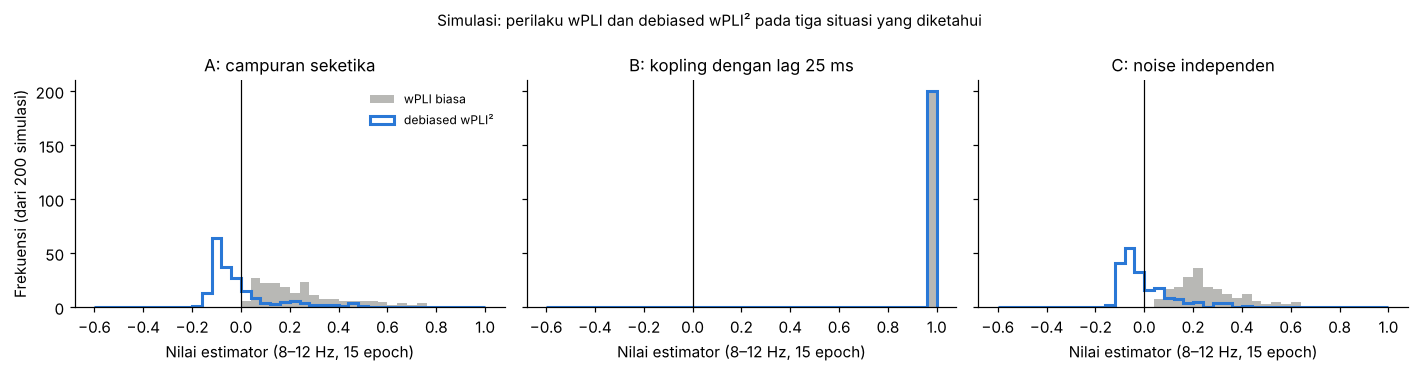

,median wpli,median wpli2_debiased,proporsi debiased < 0
A: campuran seketika,0.214,-0.064,0.710
B: kopling dengan lag 25 ms,1.000,1.000,0.000
C: noise independen,0.227,-0.037,0.655


In [16]:
def synthetic_pair(n_epochs, scenario, rng, n_times=241):
    t = np.arange(n_times) / SFREQ
    epochs = np.empty((n_epochs, 2, n_times))
    for k in range(n_epochs):
        phase = rng.uniform(0, 2 * np.pi)
        amp = 1 + 0.3 * rng.standard_normal()
        source = amp * np.sin(2 * np.pi * 10 * t + phase)
        lagged = amp * np.sin(2 * np.pi * 10 * (t - 0.025) + phase)
        noise = rng.standard_normal((2, n_times))
        if scenario == "A: campuran seketika":
            epochs[k] = [source + noise[0], 0.8 * source + noise[1]]
        elif scenario == "B: kopling dengan lag 25 ms":
            epochs[k] = [source + noise[0], lagged + noise[1]]
        else:
            epochs[k] = noise
    return epochs

def pair_score(epochs, method):
    con = spectral_connectivity_epochs(epochs, method=method, mode="multitaper", sfreq=SFREQ,
                                       fmin=CONN_FMIN, fmax=CONN_FMAX, faverage=True, verbose=False)
    return con.get_data(output="dense")[1, 0, 0]

rng_demo = np.random.default_rng(SEED)
scenarios = ["A: campuran seketika", "B: kopling dengan lag 25 ms", "C: noise independen"]
synthetic = {s: {"wpli": [], "wpli2_debiased": []} for s in scenarios}
for s in scenarios:
    for _ in range(200):
        ep_syn = synthetic_pair(15, s, rng_demo)
        for method in ("wpli", "wpli2_debiased"):
            synthetic[s][method].append(pair_score(ep_syn, method))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
bins = np.linspace(-0.6, 1.0, 41)
for ax, s in zip(axes, scenarios):
    ax.hist(synthetic[s]["wpli"], bins=bins, color="#9a9a96", alpha=0.7, label="wPLI biasa")
    ax.hist(synthetic[s]["wpli2_debiased"], bins=bins, histtype="step", lw=2, color="#2a78d6", label="debiased wPLI²")
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(s); ax.set_xlabel("Nilai estimator (8–12 Hz, 15 epoch)")
axes[0].set_ylabel("Frekuensi (dari 200 simulasi)")
axes[0].legend(fontsize=8)
fig.suptitle("Simulasi: perilaku wPLI dan debiased wPLI² pada tiga situasi yang diketahui", fontsize=10)
fig.tight_layout()
save_fig(fig, "08_wpli_synthetic_demo.png")
plt.show()

display(pd.DataFrame({s: {f"median {m}": np.median(v) for m, v in synthetic[s].items()} |
                         {"proporsi debiased < 0": np.mean(np.array(synthetic[s]["wpli2_debiased"]) < 0)}
                      for s in scenarios}).T.round(3))

**Interpretasi.** Pada situasi A (campuran seketika), kedua kanal jelas berkorelasi, tetapi wPLI biasa tidak lebih tinggi daripada pada noise independen (C): nilai positifnya hanya bias sampel kecil. Debiased wPLI² berpusat di sekitar nol, karena selisih fase nol tidak menghasilkan bagian imajiner. Inilah perlindungan terhadap volume conduction **murni seketika**. Pada situasi B, kopling dengan lag terdeteksi dengan nilai tinggi. Pada situasi C, wPLI biasa tetap positif (bias sampel kecil), sedangkan debiased wPLI² berpusat di nol dan sering **negatif**. Itulah sebabnya kita memakai estimator debiased dan tidak memotong nilai negatif.

**Batasnya:** perlindungan ini tidak sempurna. Jika dua sumber yang benar-benar berbeda tercampur ke kanal yang sama dengan bobot berbeda, atau jika referensi bersama membawa sinyal yang tertunda, wPLI² masih bisa terpengaruh.

### Implementasi pada data nyata

Fungsi berikut menghitung matriks debiased wPLI² untuk sekumpulan epoch **satu kelas**. MNE-Connectivity mengembalikan hanya segitiga bawah; kita simetriskan dan mengisi diagonal dengan `NaN` (hubungan sebuah kanal dengan dirinya sendiri bukan edge). Karena wPLI² adalah ukuran **berpasangan**, nilai untuk pasangan $(i,j)$ hanya bergantung pada sinyal $i$ dan $j$. Jadi kita cukup menghitung matriks 64×64 sekali, lalu mengambil sub-matriks 8×8 untuk setiap kandidat. Kesetaraan ini diverifikasi di bawah, bukan diasumsikan.

### Connectivity Discrimination Score (CDS)

Untuk subset $S$ dengan 8 kanal, ada $\binom{8}{2}=28$ pasangan unik tak berarah. Dengan $\widehat W^{(H)}$ dan $\widehat W^{(F)}$ matriks wPLI² kelas hands dan feet (dihitung dari epoch yang sama-sama latih atau sama-sama uji):

$$
CDS(S)=\frac1{28}\sum_{i<j,\; i,j\in S}\left|\widehat W^{(H)}_{ij}-\widehat W^{(F)}_{ij}\right|.
$$

CDS adalah rata-rata besar perbedaan konektivitas antar-kelas, dirancang oleh proyek ini. **CDS bukan biomarker neural tervalidasi.** Karena setiap $\widehat W$ mengandung noise estimasi, selisih absolutnya selalu positif bahkan jika tidak ada perbedaan sebenarnya (*noise floor*). Untuk mengurangi pengaruh jumlah trial, jumlah epoch **diseimbangkan** antar-kelas dengan subsampel acak (seed tetap) sebelum menghitung $\widehat W$.

In [17]:
N_EDGES = 28

def wpli2_debiased_matrix(X_epochs):
    # Debiased squared wPLI (8–12 Hz, multitaper) untuk satu kumpulan epoch. Diagonal = NaN.
    con = spectral_connectivity_epochs(X_epochs, method="wpli2_debiased", mode="multitaper", sfreq=SFREQ,
                                       fmin=CONN_FMIN, fmax=CONN_FMAX, faverage=True, verbose=False)
    lower = con.get_data(output="dense")[:, :, 0]
    assert np.allclose(np.triu(lower), 0), "MNE seharusnya mengisi segitiga bawah saja"
    W = lower + lower.T
    np.fill_diagonal(W, np.nan)
    return W

def balanced_indices(y, rng):
    # Subsampel acak tanpa pengembalian agar setiap kelas punya jumlah epoch sama
    n_min = np.bincount(y, minlength=2).min()
    chosen = [np.sort(rng.choice(np.flatnonzero(y == c), n_min, replace=False)) for c in (0, 1)]
    return np.sort(np.concatenate(chosen)), n_min

def class_wpli_matrices(X, y, rng):
    idx, n_per_class = balanced_indices(y, rng)
    Xb, yb = X[idx], y[idx]
    return wpli2_debiased_matrix(Xb[yb == 0]), wpli2_debiased_matrix(Xb[yb == 1]), n_per_class

def cds(W_hands, W_feet, ch_idx):
    sub_h = W_hands[np.ix_(ch_idx, ch_idx)]
    sub_f = W_feet[np.ix_(ch_idx, ch_idx)]
    iu = np.triu_indices(len(ch_idx), k=1)          # pasangan unik i < j, diagonal tidak ikut
    assert iu[0].size == N_EDGES, "CDS harus memakai tepat 28 edge"
    diff = sub_h[iu] - sub_f[iu]                     # nilai negatif dipertahankan sebelum nilai absolut
    assert np.all(np.isfinite(diff))
    return float(np.mean(np.abs(diff)))

# ---- Verifikasi pada data latih demo (AT-08, AT-09) ----
rng_check = np.random.default_rng([SEED, 999])
X_conn_demo, y_conn_demo = demo["X"][demo_train], demo["y"][demo_train]
W_h_demo, W_f_demo, n_bal_demo = class_wpli_matrices(X_conn_demo, y_conn_demo, rng_check)
sub = W_h_demo[np.ix_(idx_s01, idx_s01)]
print("Matriks 64 kanal:", W_h_demo.shape, "| sub-matriks S01:", sub.shape, "| epoch per kelas:", n_bal_demo)
print("Simetris:", np.allclose(sub, sub.T, equal_nan=True), "| diagonal NaN:", np.isnan(np.diag(sub)).all(),
      "| jumlah edge unik:", np.triu_indices(8, 1)[0].size)
print(f"Rentang nilai di luar diagonal (64×64, hands): {np.nanmin(W_h_demo):.3f} sampai {np.nanmax(W_h_demo):.3f}",
      f"| proporsi negatif: {np.mean(W_h_demo[~np.isnan(W_h_demo)] < 0):.2f}")

# Kesetaraan: sub-matriks dari 64 kanal == perhitungan langsung pada 8 kanal
idx_b, _ = balanced_indices(y_conn_demo, np.random.default_rng([SEED, 999]))
direct = wpli2_debiased_matrix(X_conn_demo[idx_b][y_conn_demo[idx_b] == 0][:, idx_s01])
max_gap = np.nanmax(np.abs(direct - sub))
print(f"Selisih maksimum sub-matriks vs perhitungan langsung 8 kanal: {max_gap:.2e}")
assert max_gap < 1e-10
print(f"CDS latih S01 pada demo: {cds(W_h_demo, W_f_demo, idx_s01):.4f}")

Matriks 64 kanal: (64, 64) | sub-matriks S01: (8, 8) | epoch per kelas: 13
Simetris: True | diagonal NaN: True | jumlah edge unik: 28
Rentang nilai di luar diagonal (64×64, hands): -0.162 sampai 1.000 | proporsi negatif: 0.37
Selisih maksimum sub-matriks vs perhitungan langsung 8 kanal: 0.00e+00
CDS latih S01 pada demo: 0.1641


**Interpretasi.** Pemeriksaan di atas memastikan empat hal teknis: matriks berukuran benar dan simetris, diagonal tidak dihitung sebagai edge, CDS memakai tepat 28 pasangan, dan memotong sub-matriks dari 64 kanal memberi hasil **identik** dengan menghitung ulang pada 8 kanal (selisih ≈ 0). Nilai di luar diagonal mencakup angka negatif, sesuai perilaku estimator debiased.

### Audit noise floor: CDSx dengan permutasi label

Untuk menilai berapa besar CDS yang muncul **hanya karena noise**, label hands/feet diacak **di dalam setiap run latih** (jumlah epoch per kelas per run tetap), lalu CDS dihitung ulang. Diulang $P$ kali:

$$
CDS_x(S) = CDS_{\text{obs}}(S) - \frac1P\sum_{p=1}^{P} CDS^{(p)}_{\text{perm}}(S).
$$

$CDS_x \approx 0$ berarti perbedaan konektivitas yang teramati tidak lebih besar dari yang diharapkan dari label acak. $CDS_x$ boleh negatif. Sesuai PROJECT_SPEC §8, **CDS adalah metrik primer untuk seleksi**; $CDS_x$ adalah **audit tambahan** yang dilaporkan, dengan pilihan subset versi CDSx dicatat sebagai analisis sensitivitas, bukan dipakai untuk evaluasi utama. Permutasi hanya dilakukan pada data latih. Dengan $P=100$, ini **bukan uji signifikansi** yang kuat.

Kini kita punya dua "penggaris": BA untuk klasifikasi dan CDS untuk konektivitas. Langkah paling kritis berikutnya adalah memakai keduanya **tanpa curang**.

---

## 09 — Validasi dan seleksi tanpa kebocoran data

> **Pertanyaan:** bagaimana memastikan skor akhir benar-benar mencerminkan kinerja pada data baru, bukan hasil "mengintip" jawaban?

### Analogi ujian

Bayangkan seorang mahasiswa menyiapkan ujian akhir. Ia boleh belajar dari soal latihan (**data latih**) dan menilai strategi belajarnya dengan try-out (**data validasi**). Tetapi jika ia memilih strategi berdasarkan **soal ujian akhir** yang bocor, nilai ujiannya tidak lagi mengukur kemampuan. Begitu juga di sini: jika subset kanal dipilih berdasarkan skor pada run uji, BA dan CDS uji menjadi terlalu optimistis.

### Mengapa pemisahan per run?

Trial di dalam satu run direkam berdekatan waktu dan berbagi kondisi yang sama (impedansi elektroda, tingkat kantuk, posisi topi). Jika trial dari run yang sama ada di data latih dan uji, model bisa belajar "ciri run" alih-alih ciri tugas. EEG juga tidak stasioner antar-sesi. Karena itu satu run utuh selalu ditahan sebagai data uji.

### Desain bersarang (nested) leave-one-run-out

```
Untuk setiap subjek:
  Outer fold 1: latih run 6+10  → uji run 14
  Outer fold 2: latih run 6+14  → uji run 10
  Outer fold 3: latih run 10+14 → uji run 6

  Di dalam setiap outer fold, hanya dengan 2 run latih (A, B):
    S_CLS : untuk 10 kandidat, latih CSP–LDA di A → nilai di B, dan latih di B → nilai di A.
            BA dalam = rata-rata dua arah. Pilih argmax (seri → ID terkecil).
    S_CONN: untuk 10 kandidat, CDS dari epoch A+B (kelas diseimbangkan). Pilih argmax (seri → ID terkecil).
    S01   : tetap, tidak dipilih dari data.
  ─── subset DIKUNCI ───
  Refit CSP–LDA pada A+B untuk S01, S_CLS, S_CONN → BA pada run uji.
  Hitung CDS pada run uji (kelas diseimbangkan) untuk ketiga subset.
```

Secara struktural, fungsi `select_subsets` di bawah **tidak menerima data uji sama sekali**. Ia hanya diberi array latih. Hasil uji dihitung setelah subset dikunci, dan tidak pernah kembali memengaruhi pilihan. Seed acak diturunkan dari `(SEED, subjek, run uji, tujuan)`, sehingga hasil dapat direproduksi persis.

In [18]:
def pick_best(scores, column):
    # argmax dengan aturan seri tetap: ID kandidat terkecil
    best = scores[column].max()
    tied = sorted(scores.loc[np.isclose(scores[column], best, rtol=0, atol=1e-12), "subset_id"])
    return tied[0], len(tied)

def select_subsets(X_tr, y_tr, run_tr, rng_balance, rng_perm, n_permutations=N_PERMUTATIONS):
    # Seluruh seleksi memakai HANYA data latih (dua run). Data uji tidak pernah masuk fungsi ini.
    train_runs = sorted(np.unique(run_tr).tolist())
    assert len(train_runs) == 2
    run_a, run_b = train_runs
    in_a, in_b = run_tr == run_a, run_tr == run_b
    rows = {sid: {"subset_id": sid, "channels": " ".join(CANDIDATES[sid]),
                  "train_run_A": run_a, "train_run_B": run_b} for sid in CANDIDATES}

    # --- Kriteria klasifikasi: validasi silang dua arah di antara run latih ---
    for sid, idx in CANDIDATE_IDX.items():
        ba_ab, _, _ = fit_and_score(X_tr[in_a][:, idx], y_tr[in_a], X_tr[in_b][:, idx], y_tr[in_b])
        ba_ba, _, _ = fit_and_score(X_tr[in_b][:, idx], y_tr[in_b], X_tr[in_a][:, idx], y_tr[in_a])
        rows[sid].update(inner_BA_AtoB=ba_ab, inner_BA_BtoA=ba_ba, inner_BA_mean=(ba_ab + ba_ba) / 2)

    # --- Kriteria konektivitas: CDS dari epoch latih gabungan, kelas diseimbangkan ---
    W_h, W_f, n_per_class = class_wpli_matrices(X_tr, y_tr, rng_balance)
    per_run = {r: class_wpli_matrices(X_tr[run_tr == r], y_tr[run_tr == r], rng_balance) for r in train_runs}
    for sid, idx in CANDIDATE_IDX.items():
        rows[sid].update(CDS_train=cds(W_h, W_f, idx),
                         CDS_train_runA=cds(per_run[run_a][0], per_run[run_a][1], idx),
                         CDS_train_runB=cds(per_run[run_b][0], per_run[run_b][1], idx),
                         n_train_per_class_CDS=n_per_class)

    # --- Audit noise floor: permutasi label di dalam setiap run latih ---
    if n_permutations > 0:
        perm = np.zeros((n_permutations, len(CANDIDATES)))
        for p in range(n_permutations):
            y_perm = y_tr.copy()
            for r in train_runs:
                in_r = run_tr == r
                y_perm[in_r] = rng_perm.permutation(y_tr[in_r])
            Wh_p, Wf_p, _ = class_wpli_matrices(X_tr, y_perm, rng_perm)
            perm[p] = [cds(Wh_p, Wf_p, idx) for idx in CANDIDATE_IDX.values()]
        for j, sid in enumerate(CANDIDATES):
            rows[sid].update(CDS_perm_mean=perm[:, j].mean(), CDS_perm_p95=np.percentile(perm[:, j], 95),
                             CDSx_train=rows[sid]["CDS_train"] - perm[:, j].mean())

    scores = pd.DataFrame(rows.values())
    scores["rank_CLS"] = scores.inner_BA_mean.rank(ascending=False, method="min").astype(int)
    scores["rank_CONN"] = scores.CDS_train.rank(ascending=False, method="min").astype(int)
    selection = {"CLS": pick_best(scores, "inner_BA_mean"), "CONN": pick_best(scores, "CDS_train")}
    if n_permutations > 0:
        selection["CONNx_audit"] = pick_best(scores, "CDSx_train")
    return scores, selection, {"W_hands": W_h, "W_feet": W_f, "n_per_class": n_per_class}

def fold_rngs(subject, test_run):
    return {name: np.random.default_rng([SEED, subject, test_run, k])
            for k, name in enumerate(["balance_train", "permutation", "balance_test"])}

def training_partition(dataset, subject, test_run):
    d = dataset[subject]
    train_mask = d["run"] != test_run
    X_tr, y_tr, run_tr = d["X"][train_mask], d["y"][train_mask], d["run"][train_mask]
    assert test_run not in set(run_tr.tolist()), "Kebocoran: run uji ada di data latih"
    return X_tr, y_tr, run_tr

### Uji kebocoran ("canary test")

Pernyataan "tidak ada kebocoran" sebaiknya diuji, bukan hanya diyakini. Kita buat salinan data di mana **run uji dirusak total**: sinyalnya diganti noise acak dan labelnya diacak. Jika seleksi benar-benar tidak menyentuh run uji, skor kandidat dan subset terpilih harus **identik** pada data asli dan data rusak (AT-07). Permutasi dimatikan di sini agar cepat; ia tidak memengaruhi pilihan S_CLS/S_CONN.

In [19]:
canary_subject, canary_test_run = SUBJECTS[0], 14
corrupted = {canary_subject: {k: v.copy() for k, v in data[canary_subject].items() if k != "meta"}}
in_test = corrupted[canary_subject]["run"] == canary_test_run
rng_c = np.random.default_rng([SEED, 12345])
corrupted[canary_subject]["X"][in_test] = rng_c.standard_normal(corrupted[canary_subject]["X"][in_test].shape) * 1e-4
corrupted[canary_subject]["y"][in_test] = rng_c.permutation(corrupted[canary_subject]["y"][in_test])

results_canary = []
for dataset in (data, corrupted):
    rngs = fold_rngs(canary_subject, canary_test_run)
    scores, selection, _ = select_subsets(*training_partition(dataset, canary_subject, canary_test_run),
                                          rngs["balance_train"], rngs["permutation"], n_permutations=0)
    results_canary.append((scores, selection))

same_scores = results_canary[0][0].equals(results_canary[1][0])
same_selection = results_canary[0][1] == results_canary[1][1]
print("Skor kandidat identik:", same_scores, "| Subset terpilih identik:", same_selection,
      "|", {k: v[0] for k, v in results_canary[0][1].items()})
assert same_scores and same_selection, "Seleksi bergantung pada run uji: ada kebocoran!"

Skor kandidat identik: True | Subset terpilih identik: True | {'CLS': 'S05', 'CONN': 'S10'}


**Interpretasi.** Skor dan pilihan subset tidak berubah sedikit pun walaupun run uji dirusak. Ini bukti empiris bahwa seleksi kanal tidak melihat run uji. Perhatikan bahwa memilih subset berdasarkan BA atau CDS **uji** akan membuat angka tampak lebih baik, tetapi angka itu tidak lagi memperkirakan kinerja pada run baru. Itulah *winner's curse* yang dihindari desain ini.

Mesin evaluasi sudah siap dan teruji. Saatnya menjalankan seluruh eksperimen.

---

## 10 — Eksekusi eksperimen lengkap

> **Pertanyaan:** apa yang terjadi ketika prosedur yang sama dijalankan untuk setiap subjek dan setiap run uji?

Fungsi `run_outer_fold` menyatukan semua langkah satu outer fold. Loop di bawahnya menjalankan semua kombinasi subjek × run uji. Setiap fold dibungkus `try/except`: jika gagal, alasannya **dicatat di `fold_log.csv`** dan ditampilkan, bukan dilewati diam-diam (AT-12).

In [20]:
def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b)

# AT-11: uji unit Jaccard
assert jaccard(CANDIDATES["S01"], CANDIDATES["S01"]) == 1.0
assert jaccard(["C3", "C4"], ["O1", "O2"]) == 0.0
assert 0 <= jaccard(CANDIDATES["S01"], CANDIDATES["S10"]) <= 1

def run_outer_fold(subject, test_run):
    rngs = fold_rngs(subject, test_run)
    X_tr, y_tr, run_tr = training_partition(data, subject, test_run)
    scores, selection, train_mats = select_subsets(X_tr, y_tr, run_tr, rngs["balance_train"], rngs["permutation"])

    # Subset DIKUNCI sebelum data uji disentuh
    locked = {"ANATOMICAL": ANATOMICAL_ID, "CLS": selection["CLS"][0], "CONN": selection["CONN"][0]}

    d = data[subject]
    test_mask = d["run"] == test_run
    X_te, y_te = d["X"][test_mask], d["y"][test_mask]
    W_h_te, W_f_te, n_te_per_class = class_wpli_matrices(X_te, y_te, rngs["balance_test"])

    j_cls_conn = jaccard(CANDIDATES[locked["CLS"]], CANDIDATES[locked["CONN"]])
    fold_rows, predictions = [], {}
    for approach, sid in locked.items():
        idx = CANDIDATE_IDX[sid]
        ba, y_pred, _ = fit_and_score(X_tr[:, idx], y_tr, X_te[:, idx], y_te)
        predictions[approach] = y_pred
        fold_rows.append({
            "subject": f"S{subject:03d}", "outer_test_run": test_run,
            "train_runs": "+".join(str(r) for r in sorted(set(run_tr.tolist()))),
            "selected_by": approach, "subset_id": sid, "channel_list": " ".join(CANDIDATES[sid]),
            "BA_test": ba, "CDS_test": cds(W_h_te, W_f_te, idx),
            "CDS_train": float(scores.loc[scores.subset_id == sid, "CDS_train"].iloc[0]),
            "inner_BA_train": float(scores.loc[scores.subset_id == sid, "inner_BA_mean"].iloc[0]),
            "n_train": len(y_tr), "n_test": len(y_te),
            "n_hands": int(np.sum(y_te == 0)), "n_feet": int(np.sum(y_te == 1)),
            "n_train_hands": int(np.sum(y_tr == 0)), "n_train_feet": int(np.sum(y_tr == 1)),
            "n_test_per_class_CDS": n_te_per_class, "n_train_per_class_CDS": train_mats["n_per_class"],
            "Jaccard_CLS_CONN": j_cls_conn,
        })
    selection_row = {
        "subject": f"S{subject:03d}", "outer_test_run": test_run,
        "S_ANATOMICAL": ANATOMICAL_ID, "S_CLS": locked["CLS"], "S_CONN": locked["CONN"],
        "n_tied_CLS": selection["CLS"][1], "n_tied_CONN": selection["CONN"][1],
        "S_CONNx_audit": selection.get("CONNx_audit", (None, 0))[0],
        "channels_CLS": " ".join(CANDIDATES[locked["CLS"]]), "channels_CONN": " ".join(CANDIDATES[locked["CONN"]]),
        "Jaccard_CLS_CONN": j_cls_conn,
        "Jaccard_ANAT_CLS": jaccard(CANDIDATES[ANATOMICAL_ID], CANDIDATES[locked["CLS"]]),
        "Jaccard_ANAT_CONN": jaccard(CANDIDATES[ANATOMICAL_ID], CANDIDATES[locked["CONN"]]),
    }
    scores.insert(0, "subject", f"S{subject:03d}")
    scores.insert(1, "outer_test_run", test_run)
    store = {"W_hands_test": W_h_te, "W_feet_test": W_f_te, "W_hands_train": train_mats["W_hands"],
             "W_feet_train": train_mats["W_feet"], "y_test": y_te, "predictions": predictions, "locked": locked}
    return fold_rows, scores, selection_row, store

In [21]:
fold_results, candidate_scores, selection_rows, fold_log, fold_store = [], [], [], [], {}
t_start_all = time.time()
for subject in SUBJECTS:
    for test_run in RUNS[::-1]:          # urutan: uji 14, 10, 6
        t0 = time.time()
        try:
            rows, scores, sel_row, store = run_outer_fold(subject, test_run)
            fold_results += rows
            candidate_scores.append(scores)
            selection_rows.append(sel_row)
            fold_store[(subject, test_run)] = store
            status, message = "ok", ""
        except Exception as err:          # dicatat, tidak disembunyikan
            status, message = "failed", f"{type(err).__name__}: {err}"
        fold_log.append({"subject": f"S{subject:03d}", "outer_test_run": test_run, "status": status,
                         "error": message, "runtime_s": round(time.time() - t0, 1)})
        print(f"S{subject:03d} | uji run {test_run:2d} | {status} | {time.time() - t0:5.1f} s {message}")
print(f"Total waktu: {time.time() - t_start_all:.0f} s")

fold_log = pd.DataFrame(fold_log)
results_per_fold = pd.DataFrame(fold_results)
candidate_training_scores = pd.concat(candidate_scores, ignore_index=True) if candidate_scores else pd.DataFrame()
subset_selection = pd.DataFrame(selection_rows)
n_failed = int((fold_log.status != "ok").sum())
print(f"Fold berhasil: {int((fold_log.status == 'ok').sum())} dari {len(fold_log)}; gagal: {n_failed}")
if n_failed:
    display(fold_log[fold_log.status != "ok"])

S001 | uji run 14 | ok |  16.1 s 


S001 | uji run 10 | ok |  16.4 s 


S001 | uji run  6 | ok |  17.6 s 


S002 | uji run 14 | ok |  18.0 s 


S002 | uji run 10 | ok |  18.0 s 


S002 | uji run  6 | ok |  18.9 s 


S003 | uji run 14 | ok |  17.6 s 


S003 | uji run 10 | ok |  16.5 s 


S003 | uji run  6 | ok |  18.0 s 
Total waktu: 157 s
Fold berhasil: 9 dari 9; gagal: 0


### Ringkasan dan ekspor

`summary_results.csv` merangkum BA dan CDS uji per subjek dan pendekatan (rata-rata dan simpangan baku antar-3 fold), ditambah baris `ALL` (rata-rata 9 fold, dengan simpangan baku antar-fold). Simpangan baku dengan 3 nilai sangat kasar, sehingga diperlakukan sebagai gambaran variasi, bukan estimasi presisi.

In [22]:
def summarise(df):
    out = (df.groupby(["subject", "selected_by"])
             .agg(n_folds=("BA_test", "size"), BA_test_mean=("BA_test", "mean"), BA_test_sd=("BA_test", "std"),
                  CDS_test_mean=("CDS_test", "mean"), CDS_test_sd=("CDS_test", "std"))
             .reset_index())
    overall = (df.groupby("selected_by")
                 .agg(n_folds=("BA_test", "size"), BA_test_mean=("BA_test", "mean"), BA_test_sd=("BA_test", "std"),
                      CDS_test_mean=("CDS_test", "mean"), CDS_test_sd=("CDS_test", "std"))
                 .reset_index().assign(subject="ALL"))
    out = pd.concat([out, overall], ignore_index=True)
    out["selected_by"] = pd.Categorical(out.selected_by, APPROACHES, ordered=True)
    return out.sort_values(["subject", "selected_by"]).reset_index(drop=True)

summary_results = summarise(results_per_fold)

results_per_fold.round(6).to_csv(OUT_DIR / "results_per_fold.csv", index=False)
candidate_training_scores.round(6).to_csv(OUT_DIR / "candidate_training_scores.csv", index=False)
subset_selection.round(6).to_csv(OUT_DIR / "subset_selection.csv", index=False)
summary_results.round(6).to_csv(OUT_DIR / "summary_results.csv", index=False)
fold_log.to_csv(OUT_DIR / "fold_log.csv", index=False)

run_metadata = {
    "executed_at_utc": pd.Timestamp.now("UTC").isoformat(), "subjects": SUBJECTS, "runs": RUNS,
    "seed": SEED, "bandpass_Hz": [L_FREQ, H_FREQ], "epoch_window_s": [TMIN, TMAX],
    "connectivity_band_Hz": [CONN_FMIN, CONN_FMAX], "connectivity_method": "wpli2_debiased, multitaper, faverage",
    "csp": {"n_components": CSP_N_COMPONENTS, "reg": None, "log": True, "norm_trace": False, "component_order": "alternate"},
    "reject_ptp_uV": REJECT_PTP_UV, "reference": "original EDF reference (no re-referencing)", "ica": "not applied",
    "n_permutations_CDSx": N_PERMUTATIONS, "montage": MONTAGE_NAME,
    "selection_rule": "argmax; ties -> smallest subset_id", "primary_connectivity_selection": "CDS_train",
    "versions": {"python": platform.python_version(), "mne": mne.__version__, "mne_connectivity": mne_connectivity.__version__,
                 "numpy": np.__version__, "scipy": scipy.__version__, "scikit_learn": sklearn.__version__,
                 "pandas": pd.__version__, "matplotlib": matplotlib.__version__, "networkx": nx.__version__},
    "data_files": file_table.to_dict(orient="records"),
}
(OUT_DIR / "run_metadata.json").write_text(json.dumps(run_metadata, indent=2, default=str))

for name in ["results_per_fold.csv", "candidate_training_scores.csv", "subset_selection.csv", "summary_results.csv",
             "fold_log.csv", "qc_channels.csv", "qc_epochs.csv", "run_metadata.json"]:
    print(f"{name:32s} {(OUT_DIR / name).stat().st_size:>8d} bytes")
display(subset_selection[["subject", "outer_test_run", "S_CLS", "S_CONN", "S_CONNx_audit", "n_tied_CLS", "n_tied_CONN", "Jaccard_CLS_CONN"]])
display(summary_results.round(3))

results_per_fold.csv                 3243 bytes
candidate_training_scores.csv       11871 bytes
subset_selection.csv                 1068 bytes
summary_results.csv                   662 bytes
fold_log.csv                          196 bytes
qc_channels.csv                     18213 bytes
qc_epochs.csv                         229 bytes
run_metadata.json                    2846 bytes


,subject,outer_test_run,S_CLS,S_CONN,S_CONNx_audit,n_tied_CLS,n_tied_CONN,Jaccard_CLS_CONN
0,S001,14,S05,S10,S10,1,1,0.000000
1,S001,10,S01,S01,S10,1,1,1.000000
2,S001,6,S05,S08,S08,1,1,0.142857
3,S002,14,S09,S05,S05,1,1,0.142857
4,S002,10,S03,S01,S01,1,1,0.454545
5,S002,6,S03,S03,S09,1,1,1.000000
6,S003,14,S02,S07,S07,1,1,0.142857
7,S003,10,S08,S10,S04,1,1,0.000000
8,S003,6,S01,S10,S10,1,1,0.000000


,subject,selected_by,n_folds,BA_test_mean,BA_test_sd,CDS_test_mean,CDS_test_sd
0,ALL,ANATOMICAL,9,0.769,0.183,0.332,0.073
1,ALL,CLS,9,0.833,0.185,0.340,0.078
2,ALL,CONN,9,0.686,0.203,0.321,0.067
3,S001,ANATOMICAL,3,0.951,0.043,0.312,0.075
4,S001,CLS,3,0.979,0.036,0.342,0.098
5,S001,CONN,3,0.844,0.144,0.260,0.020
6,S002,ANATOMICAL,3,0.750,0.108,0.391,0.059
7,S002,CLS,3,0.893,0.099,0.396,0.012
8,S002,CONN,3,0.688,0.257,0.376,0.032
9,S003,ANATOMICAL,3,0.604,0.169,0.294,0.064


**Membaca tabel seleksi.** Setiap baris adalah satu outer fold. `S_CLS` dan `S_CONN` adalah subset yang dikunci dari data latih; `n_tied_*` menunjukkan berapa kandidat berbagi skor terbaik (jika > 1, pilihan ditentukan oleh aturan seri "ID terkecil", bukan oleh keunggulan nyata). `S_CONNx_audit` adalah subset yang **akan** dipilih jika memakai CDSx; ini hanya analisis sensitivitas. Kolom `Jaccard_CLS_CONN` mengukur tumpang tindih kedua pilihan.

Tabel ringkasan adalah dasar bagian 11–13. Kita mulai dari pertanyaan yang paling familiar: klasifikasi.

---

## 11 — Hasil klasifikasi

> **Pertanyaan (RQ2):** apakah subset yang dipilih karena paling baik untuk klasifikasi pada data latih benar-benar menghasilkan balanced accuracy lebih tinggi pada run uji dibanding baseline anatomis S01?

### Cara membaca gambar

Setiap panel adalah satu subjek. Sumbu horizontal adalah tiga pendekatan seleksi. Setiap titik kecil adalah **satu run uji** (outer fold), dan garis tipis menghubungkan tiga pendekatan pada run uji yang sama, sehingga kita bisa melihat perubahan *di dalam* fold yang sama. Penanda besar adalah rata-rata subjek. Garis putus-putus di 0,5 adalah tingkat menebak acak. Panel terakhir menggabungkan semua fold.

Gambar tersimpan: outputs/figures/09_balanced_accuracy_by_approach.png


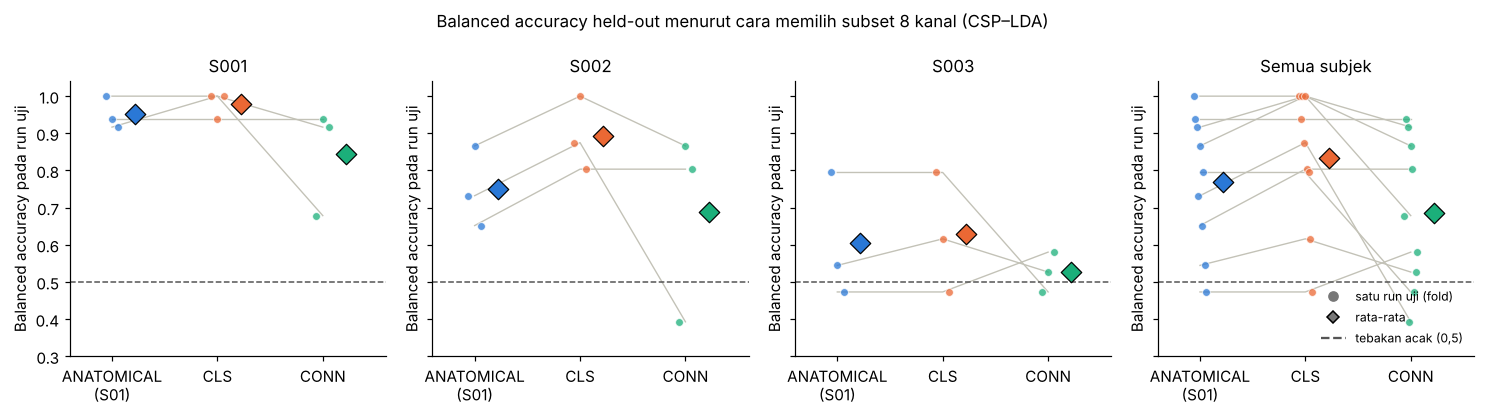

In [23]:
def paired_strip(ax, df, value, ylabel, title, ylim=None, chance=None):
    xpos = {a: i for i, a in enumerate(APPROACHES)}
    for (subject, run), grp in df.groupby(["subject", "outer_test_run"]):
        grp = grp.set_index("selected_by").reindex(APPROACHES)
        ax.plot(range(3), grp[value], color="#c3c2b7", lw=0.9, zorder=1)
    for a in APPROACHES:
        vals = df.loc[df.selected_by == a, value]
        jitter = np.linspace(-0.06, 0.06, len(vals)) if len(vals) > 1 else [0]
        ax.scatter(xpos[a] + np.asarray(jitter), vals, s=26, color=APPROACH_COLORS[a], alpha=0.75, zorder=2,
                   edgecolor="white", lw=0.6)
        ax.scatter(xpos[a] + 0.22, vals.mean(), s=90, marker="D", color=APPROACH_COLORS[a], edgecolor="black", lw=0.8, zorder=3)
    if chance is not None:
        ax.axhline(chance, color="#555555", ls="--", lw=1)
    ax.set_xticks(range(3), ["ANATOMICAL\n(S01)", "CLS", "CONN"])
    ax.set_xlim(-0.4, 2.6)
    if ylim: ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel); ax.set_title(title)

panels = SUBJECTS + ["ALL"]
fig, axes = plt.subplots(1, len(panels), figsize=(3.4 * len(panels), 3.8), sharey=True)
axes = np.atleast_1d(axes)
for ax, subject in zip(axes, panels):
    sub_df = results_per_fold if subject == "ALL" else results_per_fold[results_per_fold.subject == f"S{subject:03d}"]
    paired_strip(ax, sub_df, "BA_test", "Balanced accuracy pada run uji", "Semua subjek" if subject == "ALL" else f"S{subject:03d}",
                 ylim=(0.3, 1.04), chance=0.5)
legend_items = [Line2D([], [], marker="o", ls="", color="#777777", label="satu run uji (fold)"),
                Line2D([], [], marker="D", ls="", color="#777777", markeredgecolor="black", label="rata-rata"),
                Line2D([], [], color="#555555", ls="--", label="tebakan acak (0,5)")]
axes[-1].legend(handles=legend_items, fontsize=8, loc="lower right")
fig.suptitle("Balanced accuracy held-out menurut cara memilih subset 8 kanal (CSP–LDA)", fontsize=11)
fig.tight_layout()
save_fig(fig, "09_balanced_accuracy_by_approach.png")
plt.show()

In [24]:
wide_ba = results_per_fold.pivot_table(index=["subject", "outer_test_run"], columns="selected_by", values="BA_test")
diff_cls_anat = wide_ba["CLS"] - wide_ba["ANATOMICAL"]
overall = summary_results[summary_results.subject == "ALL"].set_index("selected_by")
lines = ["**Ringkasan otomatis (RQ2), dihitung dari `results_per_fold.csv`:**", ""]
for a in APPROACHES:
    lines.append(f"- {a}: rata-rata BA uji = {overall.loc[a, 'BA_test_mean']:.3f} (SD antar-fold {overall.loc[a, 'BA_test_sd']:.3f}, n = {int(overall.loc[a, 'n_folds'])} fold)")
lines.append(f"- CLS dibanding ANATOMICAL per fold: lebih tinggi pada {int((diff_cls_anat > 1e-12).sum())}, sama pada "
             f"{int((diff_cls_anat.abs() <= 1e-12).sum())}, lebih rendah pada {int((diff_cls_anat < -1e-12).sum())} dari {len(diff_cls_anat)} fold; "
             f"rata-rata selisih = {diff_cls_anat.mean():+.3f}.")
lines.append(f"- Fold di mana S_CLS = S01 (pilihan identik dengan baseline): {int((subset_selection.S_CLS == ANATOMICAL_ID).sum())} dari {len(subset_selection)}.")
for subject in SUBJECTS:
    tag = f"S{subject:03d}"
    s = summary_results[summary_results.subject == tag].set_index("selected_by")
    lines.append(f"- {tag}: ANATOMICAL {s.loc['ANATOMICAL', 'BA_test_mean']:.3f}, CLS {s.loc['CLS', 'BA_test_mean']:.3f}, CONN {s.loc['CONN', 'BA_test_mean']:.3f}")
show_md("\n".join(lines))

**Ringkasan otomatis (RQ2), dihitung dari `results_per_fold.csv`:**

- ANATOMICAL: rata-rata BA uji = 0.769 (SD antar-fold 0.183, n = 9 fold)
- CLS: rata-rata BA uji = 0.833 (SD antar-fold 0.185, n = 9 fold)
- CONN: rata-rata BA uji = 0.686 (SD antar-fold 0.203, n = 9 fold)
- CLS dibanding ANATOMICAL per fold: lebih tinggi pada 5, sama pada 4, lebih rendah pada 0 dari 9 fold; rata-rata selisih = +0.065.
- Fold di mana S_CLS = S01 (pilihan identik dengan baseline): 2 dari 9.
- S001: ANATOMICAL 0.951, CLS 0.979, CONN 0.844
- S002: ANATOMICAL 0.750, CLS 0.893, CONN 0.688
- S003: ANATOMICAL 0.604, CLS 0.628, CONN 0.527

### Confusion matrix

Confusion matrix di bawah **dijumlahkan dari tiga run uji** setiap subjek (jadi setiap trial muncul tepat satu kali sebagai data uji). Baris = kelas sebenarnya, kolom = prediksi. Diagonal berisi prediksi benar.

Gambar tersimpan: outputs/figures/10_confusion_matrices.png


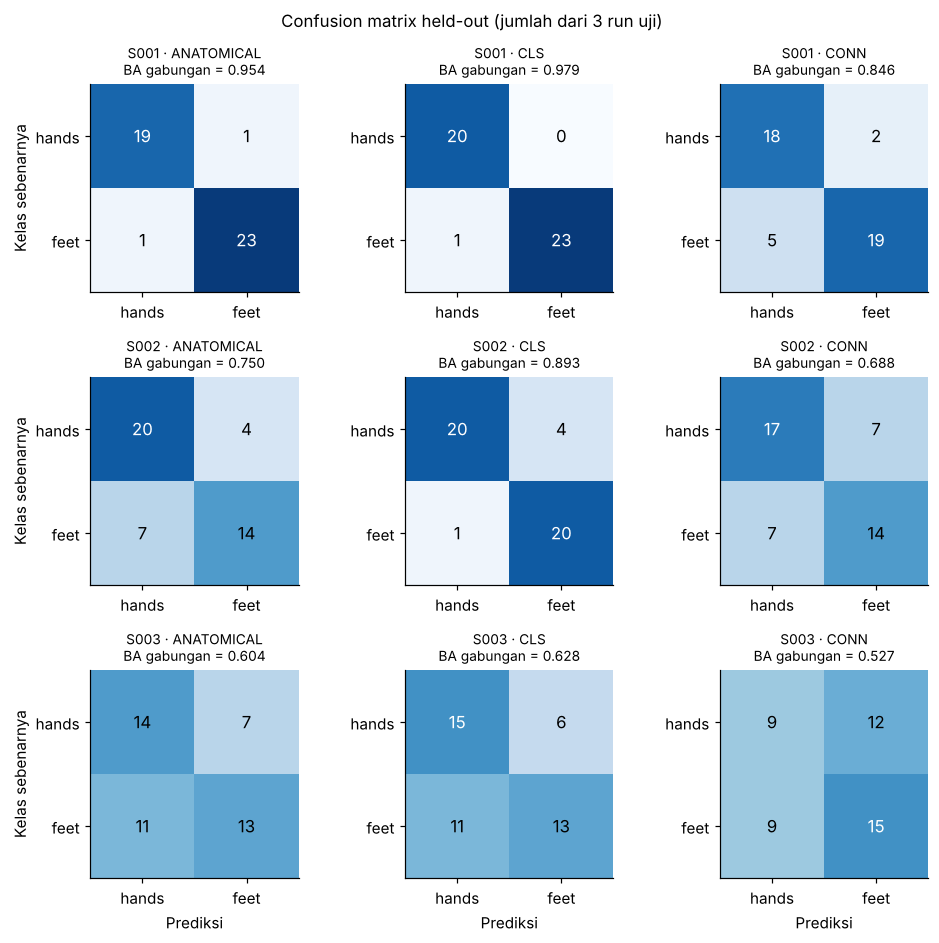

In [25]:
fig, axes = plt.subplots(len(SUBJECTS), 3, figsize=(9, 2.9 * len(SUBJECTS)), squeeze=False)
for i, subject in enumerate(SUBJECTS):
    for j, approach in enumerate(APPROACHES):
        y_true = np.concatenate([fold_store[(subject, r)]["y_test"] for r in RUNS if (subject, r) in fold_store])
        y_pred = np.concatenate([fold_store[(subject, r)]["predictions"][approach] for r in RUNS if (subject, r) in fold_store])
        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
        ax = axes[i, j]
        ax.imshow(cm, cmap="Blues", vmin=0, vmax=max(1, cm.sum(axis=1).max()))
        for (r, c), v in np.ndenumerate(cm):
            ax.text(c, r, str(v), ha="center", va="center", fontsize=11,
                    color="white" if v > cm.sum(axis=1).max() * 0.6 else "black")
        ax.set_xticks([0, 1], ["hands", "feet"]); ax.set_yticks([0, 1], ["hands", "feet"])
        ba = balanced_accuracy_score(y_true, y_pred)
        ax.set_title(f"S{subject:03d} · {approach}\nBA gabungan = {ba:.3f}", fontsize=9)
        if j == 0: ax.set_ylabel("Kelas sebenarnya")
        if i == len(SUBJECTS) - 1: ax.set_xlabel("Prediksi")
fig.suptitle("Confusion matrix held-out (jumlah dari 3 run uji)", fontsize=11)
fig.tight_layout()
save_fig(fig, "10_confusion_matrices.png")
plt.show()

**Interpretasi.** Perhatikan tiga hal. Pertama, apakah CLS benar-benar lebih tinggi daripada ANATOMICAL pada **fold yang sama** (garis abu-abu naik dari kiri ke tengah), atau hanya pada sebagian fold. Kedua, besar variasi antar-fold: dengan ±15 trial per run, satu trial bernilai sekitar 0,07 BA, sehingga selisih kecil antar-pendekatan berada dalam "resolusi" satu trial. Ketiga, ketika S_CLS sama dengan S01, kedua titik identik, bukan karena metode sama baiknya secara umum, melainkan karena pilihannya memang sama.

**Yang tidak dapat disimpulkan:** dengan 3 subjek × 3 fold, kita **tidak** dapat menyatakan bahwa seleksi berbasis klasifikasi lebih unggul secara statistik. Seleksi dari 10 kandidat yang saling tumpang tindih juga rentan *winner's curse*: kandidat yang menang di data latih sebagian menang karena keberuntungan, sehingga keunggulannya cenderung menyusut di run uji (PROJECT_SPEC §10, Risk 3).

Klasifikasi baru separuh cerita. Pertanyaan inti proyek ini adalah apakah subset terbaik-klasifikasi juga membawa perbedaan konektivitas.

---

## 12 — Hasil konektivitas

> **Pertanyaan (RQ3):** pada run uji yang belum dilihat, apakah subset terpilih-klasifikasi (CLS) menunjukkan perbedaan konektivitas hands vs feet sebesar subset yang memang dipilih untuk itu (CONN)?

Gambar pertama memakai format yang sama dengan bagian 11, tetapi sumbu vertikalnya adalah **CDS pada run uji** (kelas diseimbangkan, debiased wPLI² 8–12 Hz). Tidak ada garis "acak = 0,5" di sini, karena CDS tidak memiliki tingkat acak yang sederhana: bahkan tanpa perbedaan nyata, CDS > 0 karena noise estimasi.

Gambar tersimpan: outputs/figures/11_cds_heldout_by_approach.png


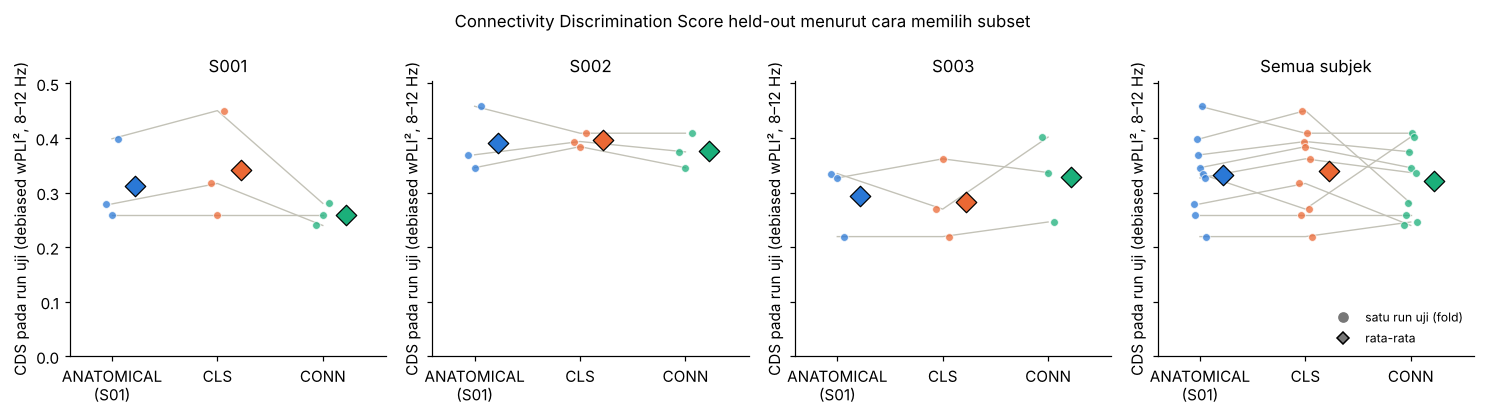

**Ringkasan otomatis (RQ3), dihitung dari `results_per_fold.csv`:**

- ANATOMICAL: rata-rata CDS uji = 0.3324 (SD antar-fold 0.0731)
- CLS: rata-rata CDS uji = 0.3404 (SD antar-fold 0.0781)
- CONN: rata-rata CDS uji = 0.3215 (SD antar-fold 0.0668)
- CDS uji CLS dibanding CONN per fold: lebih tinggi pada 5, sama pada 2 (subset identik), lebih rendah pada 2 dari 9 fold; rata-rata selisih CLS − CONN = +0.0190.
- CDS uji ANATOMICAL − CONN: rata-rata +0.0109; ANATOMICAL lebih tinggi pada 3 dari 9 fold.

In [26]:
cds_max = results_per_fold.CDS_test.max() * 1.1
fig, axes = plt.subplots(1, len(panels), figsize=(3.4 * len(panels), 3.8), sharey=True)
axes = np.atleast_1d(axes)
for ax, subject in zip(axes, panels):
    sub_df = results_per_fold if subject == "ALL" else results_per_fold[results_per_fold.subject == f"S{subject:03d}"]
    paired_strip(ax, sub_df, "CDS_test", "CDS pada run uji (debiased wPLI², 8–12 Hz)",
                 "Semua subjek" if subject == "ALL" else f"S{subject:03d}", ylim=(0, cds_max))
axes[-1].legend(handles=legend_items[:2], fontsize=8, loc="lower right")
fig.suptitle("Connectivity Discrimination Score held-out menurut cara memilih subset", fontsize=11)
fig.tight_layout()
save_fig(fig, "11_cds_heldout_by_approach.png")
plt.show()

wide_cds = results_per_fold.pivot_table(index=["subject", "outer_test_run"], columns="selected_by", values="CDS_test")
d_cls_conn = wide_cds["CLS"] - wide_cds["CONN"]
d_anat_conn = wide_cds["ANATOMICAL"] - wide_cds["CONN"]
lines = ["**Ringkasan otomatis (RQ3), dihitung dari `results_per_fold.csv`:**", ""]
for a in APPROACHES:
    lines.append(f"- {a}: rata-rata CDS uji = {overall.loc[a, 'CDS_test_mean']:.4f} (SD antar-fold {overall.loc[a, 'CDS_test_sd']:.4f})")
lines.append(f"- CDS uji CLS dibanding CONN per fold: lebih tinggi pada {int((d_cls_conn > 1e-12).sum())}, sama pada "
             f"{int((d_cls_conn.abs() <= 1e-12).sum())} (subset identik), lebih rendah pada {int((d_cls_conn < -1e-12).sum())} dari {len(d_cls_conn)} fold; "
             f"rata-rata selisih CLS − CONN = {d_cls_conn.mean():+.4f}.")
lines.append(f"- CDS uji ANATOMICAL − CONN: rata-rata {d_anat_conn.mean():+.4f}; ANATOMICAL lebih tinggi pada {int((d_anat_conn > 1e-12).sum())} dari {len(d_anat_conn)} fold.")
show_md("\n".join(lines))

### Apakah keunggulan CDS di data latih bertahan di run uji?

S_CONN dipilih justru karena CDS latihnya paling tinggi, sehingga CDS latih S_CONN tinggi **secara mekanis** (PROJECT_SPEC §10, Risk 6). Pertanyaan yang adil adalah apakah keunggulan itu bertahan pada run uji. Gambar berikut membandingkan CDS latih dan uji untuk subset yang dipilih. **Hati-hati membaca diagonal:** CDS latih dihitung dari ±13–15 epoch per kelas (dua run), sedangkan CDS uji hanya dari ±7 epoch per kelas (satu run). Dengan epoch lebih sedikit, setiap matriks wPLI² lebih bising, sehingga selisih absolutnya (dan CDS) cenderung **lebih besar** hanya karena noise. Jadi posisi titik terhadap diagonal tidak dapat dibaca langsung sebagai "bertahan" atau "menyusut". Perbandingan yang adil adalah **antar-pendekatan di dalam fold yang sama** (epoch uji identik), seperti pada gambar sebelumnya, dan urutan peringkat: apakah subset dengan CDS latih tertinggi juga punya CDS uji tertinggi. Tabel berikutnya menampilkan audit noise floor (CDSx) pada data latih.

Gambar tersimpan: outputs/figures/12_cds_train_vs_test.png


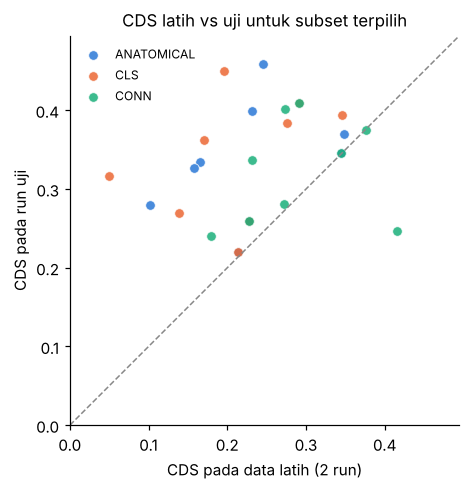

,CDS_train,CDS_perm_mean,CDS_perm_p95,CDSx_train
approach,,,,
ANATOMICAL,0.2262,0.2030,0.3021,0.0232
CLS,0.2120,0.1930,0.2778,0.0190
CONN,0.2902,0.2222,0.3254,0.0680


**Audit noise floor (100 permutasi per fold, hanya data latih):** rata-rata CDS null dari label acak adalah 0.2000, dibanding rata-rata CDS teramati semua kandidat 0.2135. Proporsi pasangan (fold × kandidat) dengan CDS teramati di atas persentil-95 null: 0.09. Pilihan berbasis CDSx sama dengan pilihan berbasis CDS pada 67% fold. Ini audit deskriptif, bukan uji signifikansi.

In [27]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for a in APPROACHES:
    sub_df = results_per_fold[results_per_fold.selected_by == a]
    ax.scatter(sub_df.CDS_train, sub_df.CDS_test, s=40, color=APPROACH_COLORS[a], label=a, edgecolor="white", lw=0.6, alpha=0.85)
lim = max(results_per_fold.CDS_train.max(), results_per_fold.CDS_test.max()) * 1.08
ax.plot([0, lim], [0, lim], color="#888888", lw=1, ls="--")
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal")
ax.set_xlabel("CDS pada data latih (2 run)"); ax.set_ylabel("CDS pada run uji")
ax.set_title("CDS latih vs uji untuk subset terpilih"); ax.legend(fontsize=8)
save_fig(fig, "12_cds_train_vs_test.png")
plt.show()

selected_long = subset_selection.melt(id_vars=["subject", "outer_test_run"], value_vars=["S_ANATOMICAL", "S_CLS", "S_CONN"],
                                      var_name="approach", value_name="subset_id")
audit = selected_long.merge(candidate_training_scores, on=["subject", "outer_test_run", "subset_id"])
if "CDSx_train" in audit:
    audit_table = (audit.groupby("approach")[["CDS_train", "CDS_perm_mean", "CDS_perm_p95", "CDSx_train"]].mean()
                   .rename(index=lambda s: s.replace("S_", "")))
    display(audit_table.round(4))
    frac_above = (candidate_training_scores.CDS_train > candidate_training_scores.CDS_perm_p95).mean()
    agree_x = (subset_selection.S_CONN == subset_selection.S_CONNx_audit).mean()
    show_md(f"**Audit noise floor ({N_PERMUTATIONS} permutasi per fold, hanya data latih):** rata-rata CDS null dari label acak "
            f"adalah {candidate_training_scores.CDS_perm_mean.mean():.4f}, dibanding rata-rata CDS teramati semua kandidat "
            f"{candidate_training_scores.CDS_train.mean():.4f}. Proporsi pasangan (fold × kandidat) dengan CDS teramati di atas persentil-95 null: "
            f"{frac_above:.2f}. Pilihan berbasis CDSx sama dengan pilihan berbasis CDS pada {agree_x:.0%} fold. "
            f"Ini audit deskriptif, bukan uji signifikansi.")

**Interpretasi.** Jika titik CONN tidak lebih tinggi daripada titik CLS dan ANATOMICAL pada sumbu vertikal (CDS uji), keunggulan CDS latih S_CONN tidak bertahan di run baru. Tabel audit memberi pembanding yang lebih jujur: `CDS_perm_mean` adalah CDS yang diharapkan **tanpa** perbedaan kelas sama sekali (hanya dari label acak). Jika CDS teramati hanya sedikit di atas angka itu, CDSx mendekati nol, dan perbedaan konektivitas yang "ditemukan" sulit dibedakan dari noise estimasi dengan ±13–15 epoch per kelas.

### Matriks konektivitas pada satu fold representatif

Fold representatif dipilih dengan aturan tetap: **fold pertama (urutan subjek, lalu run uji 14→10→6) di mana S_CLS ≠ S_CONN**, agar ketiga subset dapat dibandingkan. Jika tidak ada, fold pertama dipakai. Semua matriks dihitung pada **run uji** dengan jumlah epoch seimbang. Panel hands dan feet memakai **skala warna yang sama** untuk semua subset; panel selisih memakai skala simetris tersendiri. Diagonal (abu-abu) bukan edge. Skala tidak dipaksa ke [0,1]; nilai negatif ditampilkan apa adanya.

Fold representatif: S001, run uji 14; subset terkunci: {'ANATOMICAL': 'S01', 'CLS': 'S05', 'CONN': 'S10'}


Gambar tersimpan: outputs/figures/13_connectivity_heatmaps_S001_test14.png


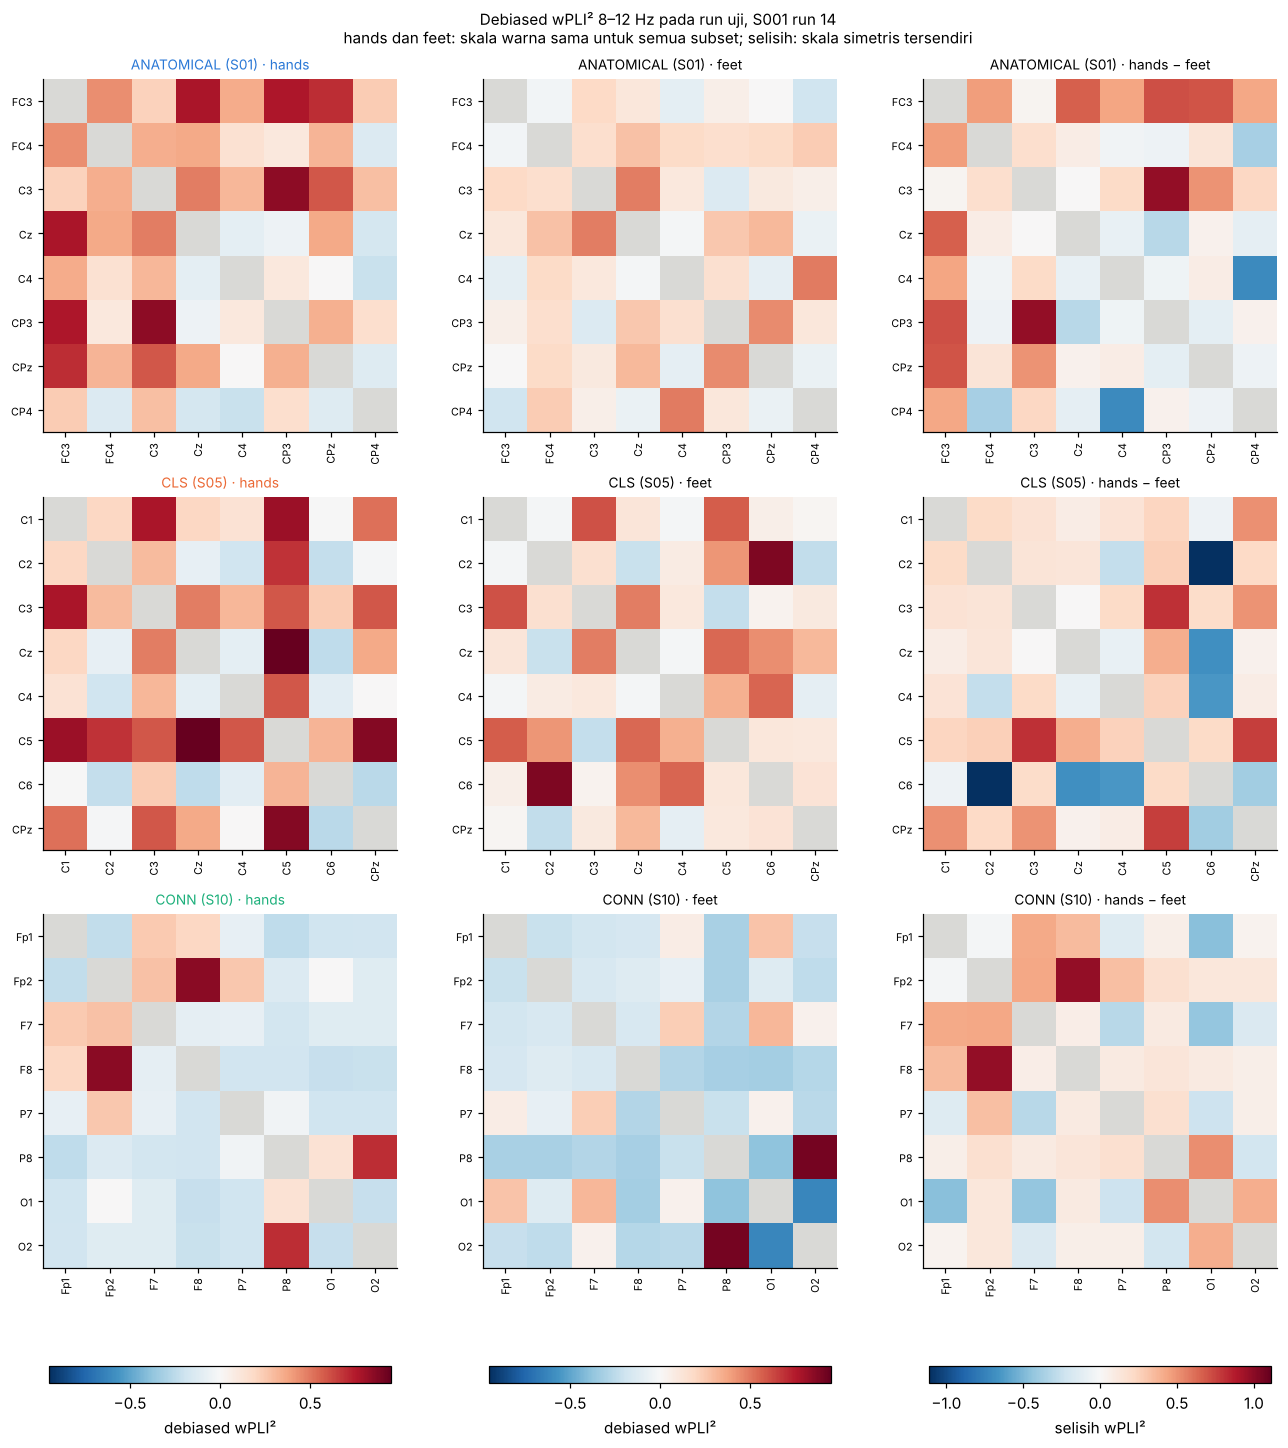

In [28]:
diff_folds = subset_selection[subset_selection.S_CLS != subset_selection.S_CONN]
rep_row = (diff_folds if len(diff_folds) else subset_selection).iloc[0]
rep_subject, rep_run = int(rep_row.subject[1:]), int(rep_row.outer_test_run)
rep = fold_store[(rep_subject, rep_run)]
print(f"Fold representatif: S{rep_subject:03d}, run uji {rep_run}; subset terkunci: {rep['locked']}")

mats = {}
for a, sid in rep["locked"].items():
    idx = CANDIDATE_IDX[sid]
    mats[a] = {"hands": rep["W_hands_test"][np.ix_(idx, idx)], "feet": rep["W_feet_test"][np.ix_(idx, idx)]}
    mats[a]["hands − feet"] = mats[a]["hands"] - mats[a]["feet"]
v_cls = max(np.nanmax(np.abs(m[k])) for m in mats.values() for k in ("hands", "feet"))
v_diff = max(np.nanmax(np.abs(m["hands − feet"])) for m in mats.values())

fig, axes = plt.subplots(3, 3, figsize=(12, 13), layout="constrained")
for i, a in enumerate(APPROACHES):
    sid = rep["locked"][a]
    for j, key in enumerate(["hands", "feet", "hands − feet"]):
        ax = axes[i, j]
        vmax = v_diff if key == "hands − feet" else v_cls
        cmap = matplotlib.colormaps["RdBu_r"].copy(); cmap.set_bad("#d9d9d6")
        im = ax.imshow(mats[a][key], cmap=cmap, vmin=-vmax, vmax=vmax)
        ax.set_xticks(range(8), CANDIDATES[sid], rotation=90, fontsize=7)
        ax.set_yticks(range(8), CANDIDATES[sid], fontsize=7)
        ax.set_title(f"{a} ({sid}) · {key}", fontsize=9, color=APPROACH_COLORS[a] if j == 0 else "black")
        if i == 2:
            fig.colorbar(im, ax=axes[:, j], shrink=0.8, location="bottom",
                         label="selisih wPLI²" if key == "hands − feet" else "debiased wPLI²")
fig.suptitle(f"Debiased wPLI² 8–12 Hz pada run uji, S{rep_subject:03d} run {rep_run}\n"
             "hands dan feet: skala warna sama untuk semua subset; selisih: skala simetris tersendiri", fontsize=10)
save_fig(fig, f"13_connectivity_heatmaps_S{rep_subject:03d}_test{rep_run}.png")
plt.show()

**Cara membaca heatmap.** Setiap sel $(i,j)$ adalah debiased wPLI² antara dua kanal. Merah = konsistensi lag fase lebih tinggi, biru = di bawah nol (lebih kecil dari yang diharapkan dari pasangan tanpa hubungan, tanda noise estimasi). Kolom ketiga adalah selisih hands − feet yang menjadi dasar CDS: CDS adalah rata-rata nilai absolut 28 sel di atas diagonal pada panel itu. Matriks dari ±7 epoch per kelas **sangat bising**; pola satu fold tidak boleh dibaca sebagai "peta jaringan otak" yang stabil (PROJECT_SPEC §5.8).

### Jaringan konektivitas pada posisi sensor

Gambar berikut menampilkan 28 edge setiap subset di atas posisi elektroda. Warna dan ketebalan menunjukkan selisih hands − feet pada run uji (skala sama untuk ketiga subset). Semua 28 edge digambar; **tidak ada ambang**, sehingga tidak ada edge yang "disembunyikan" oleh pilihan ambang visual. Garis antar-sensor adalah hubungan statistik antar-sinyal, **bukan** jalur anatomis.

Gambar tersimpan: outputs/figures/14_connectivity_network_S001_test14.png


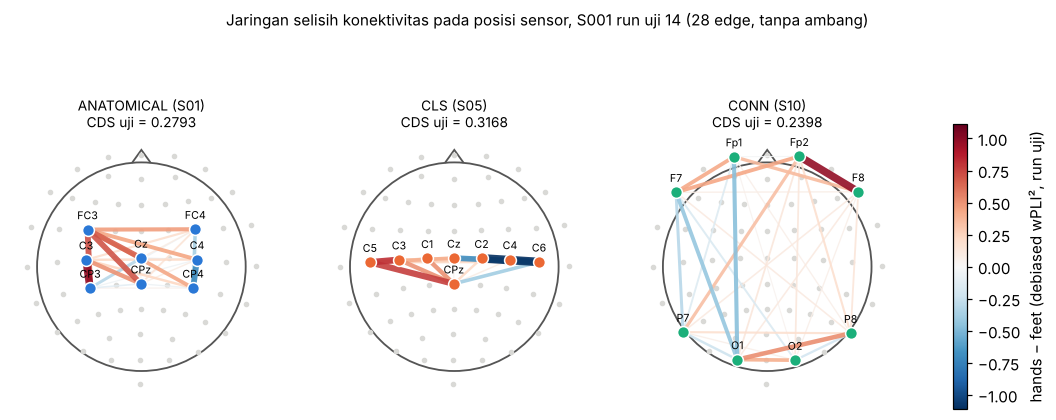

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
norm = matplotlib.colors.TwoSlopeNorm(vmin=-v_diff, vcenter=0, vmax=v_diff)
cmap = matplotlib.colormaps["RdBu_r"]
for ax, a in zip(axes, APPROACHES):
    sid = rep["locked"][a]
    idx = CANDIDATE_IDX[sid]
    graph = nx.Graph()
    for p in range(8):
        for q in range(p + 1, 8):
            graph.add_edge(CH_NAMES[idx[p]], CH_NAMES[idx[q]], weight=mats[a]["hands − feet"][p, q])
    draw_head(ax)
    ax.scatter(XY[:, 0], XY[:, 1], s=7, color="#d9d9d6", zorder=1)
    pos = {CH_NAMES[i]: XY[i] for i in idx}
    edges = sorted(graph.edges(data=True), key=lambda e: abs(e[2]["weight"]))
    for u, v, w in edges:
        ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color=cmap(norm(w["weight"])),
                lw=0.6 + 5 * abs(w["weight"]) / v_diff, alpha=0.9, zorder=2, solid_capstyle="round")
    ax.scatter([pos[n][0] for n in pos], [pos[n][1] for n in pos], s=60, color=APPROACH_COLORS[a], edgecolor="white", zorder=3)
    for n, (x, y) in pos.items():
        ax.text(x, y + 0.1, n, ha="center", fontsize=7, zorder=4)
    cds_value = results_per_fold.loc[(results_per_fold.subject == rep_row.subject) & (results_per_fold.outer_test_run == rep_run)
                                     & (results_per_fold.selected_by == a), "CDS_test"].iloc[0]
    ax.set_title(f"{a} ({sid})\nCDS uji = {cds_value:.4f}", fontsize=9)
sm = matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=axes, shrink=0.7, label="hands − feet (debiased wPLI², run uji)")
fig.suptitle(f"Jaringan selisih konektivitas pada posisi sensor, S{rep_subject:03d} run uji {rep_run} (28 edge, tanpa ambang)", fontsize=10)
save_fig(fig, f"14_connectivity_network_S{rep_subject:03d}_test{rep_run}.png")
plt.show()

**Interpretasi.** Edge tebal berwarna kuat adalah pasangan dengan selisih konektivitas terbesar antar-kelas pada run uji. Jika subset CLS dan CONN berbeda, perhatikan apakah edge besar terkumpul di area tertentu (misalnya frontal atau oksipital) yang jauh dari korteks sensorimotor. Edge semacam itu bisa mencerminkan artefak (gerak mata, ritme alfa visual) atau perbedaan SNR, bukan interaksi sensorimotor. Gambar satu fold adalah ilustrasi; kesimpulan RQ3 bertumpu pada ringkasan semua fold di atas.

Kita sudah membandingkan **kinerja** subset. Pertanyaan terakhir: seberapa mirip **isi** subset yang dipilih oleh dua kriteria?

---

## 13 — Kesesuaian antar-pendekatan seleksi

> **Pertanyaan (RQ1):** apakah kriteria klasifikasi dan kriteria konektivitas memilih kanal yang sama?

### Indeks Jaccard

Untuk dua himpunan kanal $A$ dan $B$:

$$
J(A,B)=\frac{|A\cap B|}{|A\cup B|}.
$$

$J=1$ berarti identik, $J=0$ berarti tidak berbagi satu kanal pun. Untuk dua subset berukuran 8, berbagi $m$ kanal memberi $J = m/(16-m)$; misalnya berbagi 4 kanal memberi $J = 4/12 = 0{,}33$.

**Tentang "tingkat kebetulan":** angka 0,222 dari addendum lama **tidak dipakai**, karena kandidat saling tumpang tindih dan aturan seleksi tidak memilih secara acak seragam (PROJECT_SPEC §9). Sebagai konteks deskriptif saja, ditampilkan distribusi Jaccard di antara semua 45 pasangan kandidat.

Jaccard di antara 45 pasangan kandidat: median 0.143, min 0.000, maks 0.600


,subject,outer_test_run,S_CLS,S_CONN,Jaccard_CLS_CONN,Jaccard_ANAT_CLS,Jaccard_ANAT_CONN
0,S001,14,S05,S10,0.000,0.333,0.000
1,S001,10,S01,S01,1.000,1.000,1.000
2,S001,6,S05,S08,0.143,0.333,0.600
3,S002,14,S09,S05,0.143,0.143,0.333
4,S002,10,S03,S01,0.455,0.455,1.000
5,S002,6,S03,S03,1.000,0.455,0.455
6,S003,14,S02,S07,0.143,0.455,0.231
7,S003,10,S08,S10,0.000,0.600,0.000
8,S003,6,S01,S10,0.000,1.000,0.000


Gambar tersimpan: outputs/figures/15_jaccard_overlap.png


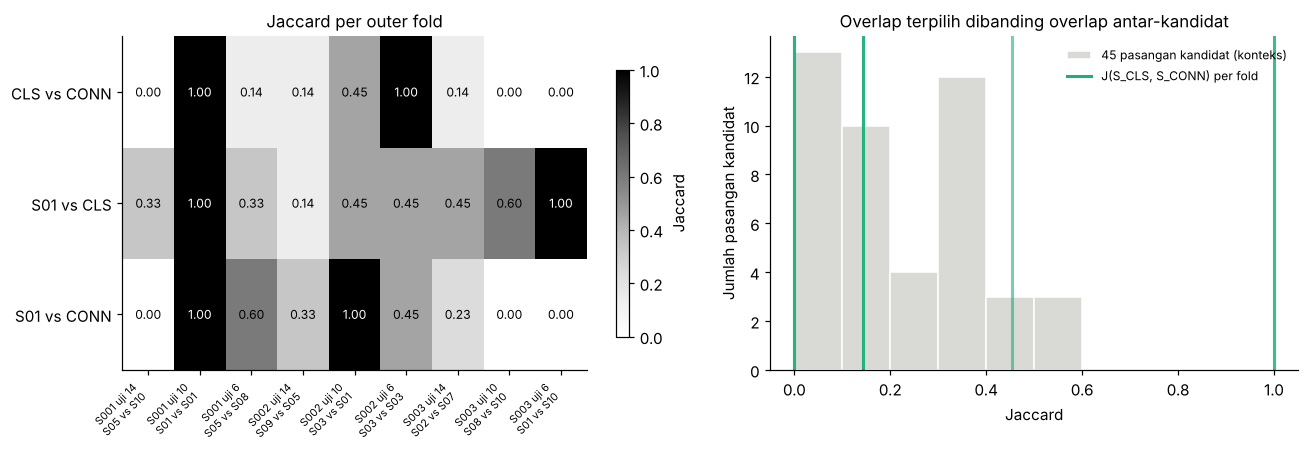

In [30]:
pair_j = [jaccard(CANDIDATES[a], CANDIDATES[b]) for i, a in enumerate(CANDIDATES) for b in list(CANDIDATES)[i + 1:]]
print(f"Jaccard di antara 45 pasangan kandidat: median {np.median(pair_j):.3f}, min {min(pair_j):.3f}, maks {max(pair_j):.3f}")

j_table = subset_selection[["subject", "outer_test_run", "S_CLS", "S_CONN", "Jaccard_CLS_CONN", "Jaccard_ANAT_CLS", "Jaccard_ANAT_CONN"]]
display(j_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
labels = [f"{r.subject} uji {r.outer_test_run}\n{r.S_CLS} vs {r.S_CONN}" for r in subset_selection.itertuples()]
values = subset_selection[["Jaccard_CLS_CONN", "Jaccard_ANAT_CLS", "Jaccard_ANAT_CONN"]].to_numpy()
im = axes[0].imshow(values.T, cmap="Greys", vmin=0, vmax=1, aspect="auto")
for (r, c), v in np.ndenumerate(values.T):
    axes[0].text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.6 else "black")
axes[0].set_yticks(range(3), ["CLS vs CONN", "S01 vs CLS", "S01 vs CONN"])
axes[0].set_xticks(range(len(labels)), labels, fontsize=7, rotation=45, ha="right")
axes[0].set_title("Jaccard per outer fold")
fig.colorbar(im, ax=axes[0], shrink=0.8, label="Jaccard")
axes[1].hist(pair_j, bins=np.linspace(0, 1, 11), color="#d9d9d6", edgecolor="white", label="45 pasangan kandidat (konteks)")
for v in subset_selection.Jaccard_CLS_CONN:
    axes[1].axvline(v, color=APPROACH_COLORS["CONN"], lw=2, alpha=0.6)
axes[1].plot([], [], color=APPROACH_COLORS["CONN"], lw=2, label="J(S_CLS, S_CONN) per fold")
axes[1].set_xlabel("Jaccard"); axes[1].set_ylabel("Jumlah pasangan kandidat")
axes[1].set_title("Overlap terpilih dibanding overlap antar-kandidat"); axes[1].legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "15_jaccard_overlap.png")
plt.show()

### Kanal mana yang sering dipilih?

Peta berikut menghitung, untuk setiap elektroda, berapa kali ia masuk subset terpilih di semua outer fold. Ukuran dan warna titik menunjukkan frekuensi. Peta ini juga menunjukkan **stabilitas seleksi**: jika pilihan berganti-ganti antar-fold, frekuensi tersebar ke banyak kanal.

Gambar tersimpan: outputs/figures/16_selection_frequency_sensor_map.png


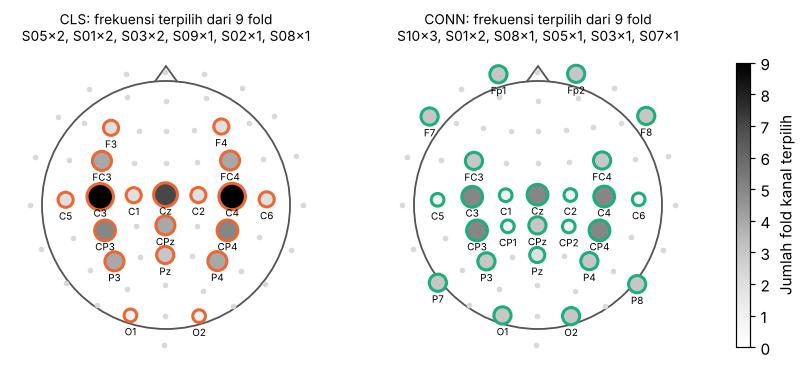

,unique_S_CLS,unique_S_CONN,S_CLS_list,S_CONN_list
subject,,,,
S001,2,3,"S05, S01, S05","S10, S01, S08"
S002,2,3,"S09, S03, S03","S05, S01, S03"
S003,3,2,"S02, S08, S01","S07, S10, S10"


**Ringkasan otomatis (RQ1):** S_CLS = S_CONN pada 2 dari 9 fold. Jaccard CLS–CONN: rata-rata 0.320, median 0.143, rentang 0.000–1.000. Sebagai konteks, median Jaccard antar-pasangan kandidat adalah 0.143.

In [31]:
n_folds_ok = len(subset_selection)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
for ax, (approach, column) in zip(axes, [("CLS", "S_CLS"), ("CONN", "S_CONN")]):
    counts = pd.Series(0, index=CH_NAMES)
    for sid in subset_selection[column]:
        counts[CANDIDATES[sid]] += 1
    draw_head(ax)
    ax.scatter(XY[:, 0], XY[:, 1], s=7, color="#d9d9d6")
    used = counts[counts > 0]
    idx = [CH_NAMES.index(c) for c in used.index]
    sc = ax.scatter(XY[idx, 0], XY[idx, 1], s=40 + 260 * used / n_folds_ok, c=used, cmap="Greys", vmin=0, vmax=n_folds_ok,
                    edgecolor=APPROACH_COLORS[approach], lw=2, zorder=3)
    for c in used.index:
        i = CH_NAMES.index(c)
        ax.text(XY[i, 0], XY[i, 1] - 0.16, c, ha="center", fontsize=6.5)
    picks = subset_selection[column].value_counts()
    ax.set_title(f"{approach}: frekuensi terpilih dari {n_folds_ok} fold\n" + ", ".join(f"{k}×{v}" for k, v in picks.items()), fontsize=9)
fig.colorbar(sc, ax=axes, shrink=0.7, label="Jumlah fold kanal terpilih")
save_fig(fig, "16_selection_frequency_sensor_map.png")
plt.show()

stability = subset_selection.groupby("subject").agg(unique_S_CLS=("S_CLS", "nunique"), unique_S_CONN=("S_CONN", "nunique"),
                                                    S_CLS_list=("S_CLS", lambda s: ", ".join(s)), S_CONN_list=("S_CONN", lambda s: ", ".join(s)))
display(stability)
jc = subset_selection.Jaccard_CLS_CONN
show_md(f"**Ringkasan otomatis (RQ1):** S_CLS = S_CONN pada {int((jc == 1).sum())} dari {len(jc)} fold. "
        f"Jaccard CLS–CONN: rata-rata {jc.mean():.3f}, median {jc.median():.3f}, rentang {jc.min():.3f}–{jc.max():.3f}. "
        f"Sebagai konteks, median Jaccard antar-pasangan kandidat adalah {np.median(pair_j):.3f}.")

### Analisis asosiasi tambahan (RQ4, opsional dalam spesifikasi)

RQ4 termasuk dalam spesifikasi final sebagai analisis **deskriptif** dan hanya memakai skor **latih** yang sudah dihitung, sehingga tidak memengaruhi analisis utama. Untuk setiap fold, kita hitung korelasi Spearman antara BA validasi-dalam dan CDS latih di 10 kandidat:

$$
\rho = 1 - \frac{6\sum_k d_k^2}{n(n^2-1)}, \qquad n=10,
$$

dengan $d_k$ selisih peringkat kandidat $k$ pada kedua skor (rumus tanpa seri; implementasi `scipy` menangani seri). $\rho>0$ berarti kandidat yang bagus untuk klasifikasi cenderung juga ber-CDS tinggi. **Tidak ada p-value**: 10 kandidat yang saling tumpang tindih bukan sampel independen.

,subject,outer_test_run,spearman_rho_innerBA_vs_CDStrain
0,S001,14,-0.309
1,S001,10,0.377
2,S001,6,0.511
3,S002,14,0.067
4,S002,10,0.188
5,S002,6,0.888
6,S003,14,-0.212
7,S003,10,-0.309
8,S003,6,0.085


Gambar tersimpan: outputs/figures/17_rq4_innerBA_vs_CDStrain.png


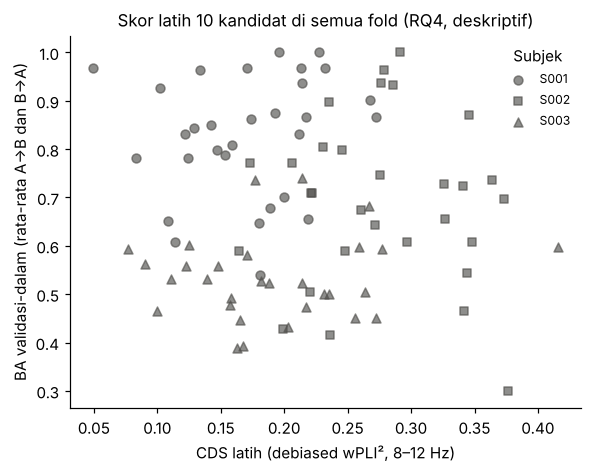

**Ringkasan otomatis (RQ4):** ρ Spearman per fold berkisar -0.31 sampai +0.89 (median +0.09; positif pada 6 dari 9 fold). Deskriptif saja; bukan uji hipotesis.

In [32]:
rq4_rows = []
for (subject, run), grp in candidate_training_scores.groupby(["subject", "outer_test_run"], sort=False):
    rho = spearmanr(grp.inner_BA_mean, grp.CDS_train).statistic
    rq4_rows.append({"subject": subject, "outer_test_run": run, "spearman_rho_innerBA_vs_CDStrain": rho})
rq4 = pd.DataFrame(rq4_rows)
rq4.round(4).to_csv(OUT_DIR / "rq4_spearman_training.csv", index=False)
display(rq4.round(3))

fig, ax = plt.subplots(figsize=(6, 4.4))
markers = ["o", "s", "^"]
for m, subject in zip(markers, candidate_training_scores.subject.unique()):
    grp = candidate_training_scores[candidate_training_scores.subject == subject]
    ax.scatter(grp.CDS_train, grp.inner_BA_mean, marker=m, s=34, color="#52514e", alpha=0.65, label=subject)
ax.set_xlabel("CDS latih (debiased wPLI², 8–12 Hz)")
ax.set_ylabel("BA validasi-dalam (rata-rata A→B dan B→A)")
ax.set_title("Skor latih 10 kandidat di semua fold (RQ4, deskriptif)")
ax.legend(title="Subjek", fontsize=8)
save_fig(fig, "17_rq4_innerBA_vs_CDStrain.png")
plt.show()
show_md(f"**Ringkasan otomatis (RQ4):** ρ Spearman per fold berkisar {rq4.iloc[:, 2].min():+.2f} sampai {rq4.iloc[:, 2].max():+.2f} "
        f"(median {rq4.iloc[:, 2].median():+.2f}; positif pada {int((rq4.iloc[:, 2] > 0).sum())} dari {len(rq4)} fold). "
        "Deskriptif saja; bukan uji hipotesis.")

**Interpretasi.** Jaccard menjawab apakah dua kriteria **memilih kanal yang sama**; RQ4 menjawab apakah **peringkat** kandidat menurut dua kriteria searah. Keduanya bisa berbeda: dua kriteria dapat setuju secara umum (ρ positif) tetapi tetap memilih juara yang berbeda, atau sebaliknya. Ketidakstabilan pilihan antar-fold juga merupakan temuan: dengan ±30 trial latih, skor kandidat yang berdekatan mudah bertukar urutan.

Dengan semua hasil di tangan, kita bisa menjawab pertanyaan penelitian secara jujur, termasuk batas-batasnya.

---

## 14 — Diskusi ilmiah dan keterbatasan

> **Pertanyaan:** apa yang benar-benar didukung oleh hasil, dan apa yang masih spekulasi?

### Jawaban atas pertanyaan penelitian

Jawaban di bawah dihasilkan **otomatis dari CSV hasil**. Bahasa kesimpulannya sengaja deskriptif.

In [33]:
n_fold = len(subset_selection)
n_same = int((subset_selection.S_CLS == subset_selection.S_CONN).sum())
ba_o = overall["BA_test_mean"]; cds_o = overall["CDS_test_mean"]
answers = [
    f"**RQ1 — kesamaan subset.** Kriteria klasifikasi dan konektivitas memilih subset yang sama pada {n_same} dari {n_fold} fold "
    f"(Jaccard rata-rata {subset_selection.Jaccard_CLS_CONN.mean():.3f}). "
    + ("H1 (subset tidak selalu identik) **konsisten** dengan data ini." if n_same < n_fold else "H1 **tidak didukung**: kedua kriteria selalu memilih subset yang sama."),
    f"**RQ2 — klasifikasi.** BA uji rata-rata: ANATOMICAL {ba_o['ANATOMICAL']:.3f}, CLS {ba_o['CLS']:.3f}, CONN {ba_o['CONN']:.3f}. "
    f"CLS ≥ ANATOMICAL pada {int((diff_cls_anat >= -1e-12).sum())} dari {len(diff_cls_anat)} fold (lebih tinggi pada {int((diff_cls_anat > 1e-12).sum())}). "
    "Karena desain hanya 3 subjek dan pilihan berasal dari kandidat yang tumpang tindih, ini **bukan** bukti superioritas.",
    f"**RQ3 — konektivitas held-out.** CDS uji rata-rata: ANATOMICAL {cds_o['ANATOMICAL']:.4f}, CLS {cds_o['CLS']:.4f}, CONN {cds_o['CONN']:.4f}. "
    f"Pada fold dengan subset berbeda, CLS lebih tinggi daripada CONN pada {int((d_cls_conn > 1e-12).sum())} dan lebih rendah pada {int((d_cls_conn < -1e-12).sum())} fold. "
    + ("Subset yang dipilih untuk konektivitas **tidak** mempertahankan keunggulan CDS-nya di run uji secara rata-rata. "
       if cds_o["CONN"] <= max(cds_o["CLS"], cds_o["ANATOMICAL"]) else
       "Subset CONN mempertahankan CDS uji tertinggi secara rata-rata. ")
    + "Interpretasi harus memperhitungkan noise floor (bagian 12).",
    f"**RQ4 — asosiasi skor latih.** Median ρ Spearman antara BA validasi-dalam dan CDS latih = {rq4.iloc[:, 2].median():+.2f} "
    f"(rentang {rq4.iloc[:, 2].min():+.2f} sampai {rq4.iloc[:, 2].max():+.2f}); deskriptif tanpa p-value.",
]
show_md("\n\n".join(answers))

# Catatan QC: apakah subset terpilih memuat kanal yang ditandai QC pada subjek yang sama?
qc_notes = []
for r in subset_selection.itertuples():
    for approach, sid in (("CLS", r.S_CLS), ("CONN", r.S_CONN)):
        bad = sorted({c for (s, c) in flag_lookup if f"S{s:03d}" == r.subject and c in CANDIDATES[sid]})
        if bad:
            qc_notes.append(f"{r.subject} uji run {r.outer_test_run}: S_{approach} = {sid} memuat kanal bertanda QC {', '.join(bad)}")
show_md("**Catatan QC pada subset terpilih:** " + ("; ".join(qc_notes) + "." if qc_notes else "tidak ada subset terpilih yang memuat kanal bertanda QC."))

**RQ1 — kesamaan subset.** Kriteria klasifikasi dan konektivitas memilih subset yang sama pada 2 dari 9 fold (Jaccard rata-rata 0.320). H1 (subset tidak selalu identik) **konsisten** dengan data ini.

**RQ2 — klasifikasi.** BA uji rata-rata: ANATOMICAL 0.769, CLS 0.833, CONN 0.686. CLS ≥ ANATOMICAL pada 9 dari 9 fold (lebih tinggi pada 5). Karena desain hanya 3 subjek dan pilihan berasal dari kandidat yang tumpang tindih, ini **bukan** bukti superioritas.

**RQ3 — konektivitas held-out.** CDS uji rata-rata: ANATOMICAL 0.3324, CLS 0.3404, CONN 0.3215. Pada fold dengan subset berbeda, CLS lebih tinggi daripada CONN pada 5 dan lebih rendah pada 2 fold. Subset yang dipilih untuk konektivitas **tidak** mempertahankan keunggulan CDS-nya di run uji secara rata-rata. Interpretasi harus memperhitungkan noise floor (bagian 12).

**RQ4 — asosiasi skor latih.** Median ρ Spearman antara BA validasi-dalam dan CDS latih = +0.09 (rentang -0.31 sampai +0.89); deskriptif tanpa p-value.

**Catatan QC pada subset terpilih:** S003 uji run 10: S_CONN = S10 memuat kanal bertanda QC Fp1, Fp2; S003 uji run 6: S_CONN = S10 memuat kanal bertanda QC Fp1, Fp2.

### Kaitan dengan literatur (hanya yang terverifikasi di Stage 1)

- **ERD dan CSP.** Fakta bahwa subset sensorimotor memberi klasifikasi baik sejalan dengan prinsip ERD/ERS [pfurtscheller1999] dan justifikasi spatial filtering [blankertz2008]. Itu prinsip mapan, bukan temuan baru proyek ini.
- **Seleksi berbasis klasifikasi.** Feng dkk. [feng2019] menunjukkan seleksi berbasis CSP-rank dengan LDA. Teks lengkap mereka (satu-satunya yang dibaca penuh di Stage 1) tidak menyatakan bahwa jumlah kanal optimal dipilih terisolasi dari fold uji. Desain bersarang di sini sengaja mencegah sumber optimisme seperti itu.
- **Seleksi berbasis hubungan antar-kanal.** Park & Chung [parkchung2020] memakai selisih korelasi antar-kelas; CDS adalah kerabat konseptualnya dengan estimator berbeda. Lou dkk. [lou2023] memakai functional connectivity untuk seleksi pada dataset yang sama, tetapi rincian estimatornya belum diaudit dari teks lengkap, sehingga hasil di sini **tidak dapat** dibandingkan langsung dengan angka mereka. Mereka juga bekerja lintas subjek dengan model deep learning, sedangkan proyek ini within-subject dengan CSP–LDA.
- **Estimator.** Penggunaan debiased wPLI² mengikuti Vinck dkk. [vinck2011]; prinsip bagian imajiner untuk menekan pengaruh volume conduction seketika berasal dari Nolte dkk. [nolte2004].

### Keterbatasan

1. **Ukuran sampel sangat kecil.** Tiga subjek, tiga run, ±15 trial per run. BA berbutir ±0,07 per trial; konektivitas diestimasi dari ±7 epoch per kelas pada run uji. Semua hasil eksploratif; skor per subjek lebih bermakna daripada rata-rata gabungan.
2. **Volume conduction dan source mixing.** wPLI² menekan pencampuran seketika, tetapi tidak menghapus pengaruh campuran beberapa sumber dengan bobot berbeda. Hubungan yang terukur adalah antar-**sinyal sensor**, bukan antar-region otak.
3. **Efek referensi.** Data memakai referensi rekaman asli tanpa re-referencing. Referensi bersama dapat menyuntikkan komponen yang sama ke semua kanal. Pilihan referensi lain (misalnya average atau Laplacian) dapat mengubah nilai konektivitas; tidak diuji di sini.
4. **Estimasi konektivitas yang bising.** Dengan sedikit epoch, matriks wPLI² per kelas memiliki varians besar, dan CDS selalu > 0 bahkan tanpa perbedaan nyata. Audit CDSx memperlihatkan seberapa dekat CDS teramati dengan noise floor.
5. **CDS bukan biomarker.** CDS adalah ukuran deskriptif buatan proyek, tidak tervalidasi secara neurofisiologis. CDS juga dapat dipengaruhi perbedaan daya/SNR antar-kelas, bukan hanya kopling fase. *Kontrol eksplisit CDSx vs ERD ("S5") yang disebut di `THEORETICAL_FRAMEWORK.md` tidak tercantum di `PROJECT_SPEC.md` final, sehingga tidak diimplementasikan dan dicatat sebagai pekerjaan lanjutan.*
6. **Ketidakstabilan seleksi dan winner's curse.** Pilihan subset dapat berganti antar-fold; seri pada BA validasi-dalam diselesaikan dengan aturan "ID terkecil", yang mewarisi urutan penomoran kandidat.
7. **Ruang pencarian terbatas.** Hanya 10 dari $\sim 4{,}4\times10^{9}$ kemungkinan subset 8 kanal. Hasil tidak menjawab "8 vs 64 kanal" dan tidak menyimulasikan perangkat 8 elektroda fisik.
8. **Ambang penolakan epoch** (400 µV) ditetapkan setelah melihat distribusi amplitudo (tanpa label/skor); ambang lain dapat sedikit mengubah set epoch.

### Bukti vs spekulasi

| Pernyataan | Status |
|---|---|
| Nilai BA, CDS, Jaccard, dan ρ di atas | **Bukti** (dihitung, dapat direproduksi) |
| Seleksi tidak melihat run uji | **Bukti** (uji canary di bagian 09) |
| Perbedaan antar-pendekatan berlaku umum pada populasi | **Tidak didukung** (n = 3) |
| Kanal frontal/oksipital terpilih oleh CDS karena artefak mata atau alfa visual | **Hipotesis** yang masuk akal, belum diuji |
| Perbedaan CDS mencerminkan interaksi neural antar-area | **Spekulasi**; tidak dapat disimpulkan dari data sensor |

## 15 — Kesimpulan dan reproduksibilitas

### Temuan ringkas

In [34]:
show_md("\n".join([
    f"- Eksperimen dijalankan pada {len(SUBJECTS)} subjek × {len(RUNS)} run uji = {len(fold_log)} outer fold; "
    f"berhasil {int((fold_log.status == 'ok').sum())}, gagal {int((fold_log.status != 'ok').sum())}.",
    f"- Klasifikasi CSP–LDA 8 kanal: BA uji rata-rata {ba_o['ANATOMICAL']:.3f} (S01), {ba_o['CLS']:.3f} (CLS), {ba_o['CONN']:.3f} (CONN).",
    f"- Diskriminasi konektivitas held-out (CDS): {cds_o['ANATOMICAL']:.4f} (S01), {cds_o['CLS']:.4f} (CLS), {cds_o['CONN']:.4f} (CONN).",
    f"- Kedua kriteria memilih subset identik pada {n_same}/{n_fold} fold; Jaccard CLS–CONN rata-rata {subset_selection.Jaccard_CLS_CONN.mean():.3f}.",
    "- Semua pernyataan bersifat deskriptif untuk tiga subjek; tidak ada klaim signifikansi statistik.",
]))

- Eksperimen dijalankan pada 3 subjek × 3 run uji = 9 outer fold; berhasil 9, gagal 0.
- Klasifikasi CSP–LDA 8 kanal: BA uji rata-rata 0.769 (S01), 0.833 (CLS), 0.686 (CONN).
- Diskriminasi konektivitas held-out (CDS): 0.3324 (S01), 0.3404 (CLS), 0.3215 (CONN).
- Kedua kriteria memilih subset identik pada 2/9 fold; Jaccard CLS–CONN rata-rata 0.320.
- Semua pernyataan bersifat deskriptif untuk tiga subjek; tidak ada klaim signifikansi statistik.

### Peluang penelitian lanjutan

- Menambah subjek (spesifikasi mengizinkan S004–S005 setelah pipeline stabil) agar perbedaan per subjek dapat diringkas lebih andal.
- Kontrol eksplisit apakah CDS digerakkan oleh perbedaan daya/ERD (analisis "S5" di kerangka teori).
- Menguji sensitivitas terhadap skema referensi (average, Laplacian) dan band konektivitas (beta).
- Benchmark Jaccard berbasis simulasi dengan asumsi aturan seleksi yang eksplisit.

### Lingkungan perangkat lunak dan parameter

In [35]:
versions = pd.DataFrame([{"package": k, "version": v} for k, v in run_metadata["versions"].items()])
display(versions)
params = {k: v for k, v in run_metadata.items() if k not in ("versions", "data_files")}
display(pd.DataFrame({"parameter": list(params), "value": [str(v) for v in params.values()]}))

,package,version
0,python,3.13.16
1,mne,1.13.2
2,mne_connectivity,0.9.0
3,numpy,2.5.3
4,scipy,1.18.1
5,scikit_learn,1.9.1
6,pandas,3.0.5
7,matplotlib,3.11.2
8,networkx,3.7


,parameter,value
0,executed_at_utc,2026-10-19T06:04:23.639461+00:00
1,subjects,"[1, 2, 3]"
2,runs,"[6, 10, 14]"
3,seed,20261019
4,bandpass_Hz,"[7.0, 30.0]"
5,epoch_window_s,"[1.0, 2.5]"
6,connectivity_band_Hz,"[8.0, 12.0]"
7,connectivity_method,"wpli2_debiased, multitaper, faverage"
8,csp,"{'n_components': 4, 'reg': None, 'log': True, ..."
9,reject_ptp_uV,400.0


### Status acceptance test (PROJECT_SPEC §13)

Tabel berikut dibuat dari pemeriksaan yang benar-benar dijalankan di notebook ini. Butir yang tidak dapat dicek dari dalam notebook ditandai demikian.

In [36]:
ok_all = bool((fold_log.status == "ok").all())
at = [
    ("AT-01", "EDF S1 run 6/10/14 terunduh, event ditampilkan", "lulus (bagian 02, checksum resmi cocok)"),
    ("AT-02", "T1/T2 = both fists/feet imagery khusus run 6/10/14", "lulus (assert run ∈ {6,10,14}; makna label dari dokumentasi PhysioNet)"),
    ("AT-03", "160 Hz, 64 kanal, satuan konsisten", "lulus (assert bagian 02)"),
    ("AT-04", "10 kandidat × 8 kanal unik dan tersedia", "lulus (assert bagian 06)"),
    ("AT-05", "Label/run benar, tak ada trial run uji di latih", "lulus (assert bagian 05 dan training_partition)"),
    ("AT-06", "CSP/LDA di-fit hanya pada data latih", "lulus (Pipeline per fold; fit_and_score)"),
    ("AT-07", "Held-out tidak dipakai memilih subset", "lulus (uji canary bagian 09)"),
    ("AT-08", "wPLI² 8×8 simetris, diagonal dinetralkan", "lulus (bagian 08)"),
    ("AT-09", "CDS tepat 28 edge, jumlah epoch seimbang", "lulus (assert dalam cds dan balanced_indices)"),
    ("AT-10", "Permutasi dibuktikan output dan seed", f"lulus ({N_PERMUTATIONS} permutasi/fold, seed {SEED}; kolom CDS_perm_* di CSV)" if N_PERMUTATIONS > 0 else "tidak dijalankan"),
    ("AT-11", "Jaccard 0..1, identik = 1, disjoint = 0", "lulus (uji unit bagian 10)"),
    ("AT-12", "Semua fold tiga subjek tanpa error", "lulus" if ok_all and len(SUBJECTS) >= 3 else f"lihat fold_log.csv (subjek dijalankan: {SUBJECTS})"),
    ("AT-13", "Gambar/CSV dari hasil nyata; RESULTS_SUMMARY = CSV", "CSV & gambar: lulus; kecocokan RESULTS_SUMMARY dicek di luar notebook"),
    ("AT-14", "Run-all dari kernel bersih", "dicek di luar notebook (eksekusi nbconvert)"),
    ("AT-15", "Setiap sumber merujuk BibTeX", "kunci sitasi di notebook = kunci di references.bib"),
    ("AT-16", "Tidak ada klaim 'signifikan' dari 3 subjek", "lulus (tidak ada uji/klaim signifikansi)"),
    ("AT-17", "Interpretasi grafik menjawab RQ spesifik", "lulus (bagian 11–13)"),
    ("AT-18", "LaTeX Stage 3 hanya dari hasil terverifikasi", "di luar cakupan Stage 2"),
]
display(pd.DataFrame(at, columns=["ID", "Uji", "Status"]))

,ID,Uji,Status
0,AT-01,"EDF S1 run 6/10/14 terunduh, event ditampilkan","lulus (bagian 02, checksum resmi cocok)"
1,AT-02,T1/T2 = both fists/feet imagery khusus run 6/1...,"lulus (assert run ∈ {6,10,14}; makna label dar..."
2,AT-03,"160 Hz, 64 kanal, satuan konsisten",lulus (assert bagian 02)
3,AT-04,10 kandidat × 8 kanal unik dan tersedia,lulus (assert bagian 06)
4,AT-05,"Label/run benar, tak ada trial run uji di latih",lulus (assert bagian 05 dan training_partition)
5,AT-06,CSP/LDA di-fit hanya pada data latih,lulus (Pipeline per fold; fit_and_score)
6,AT-07,Held-out tidak dipakai memilih subset,lulus (uji canary bagian 09)
7,AT-08,"wPLI² 8×8 simetris, diagonal dinetralkan",lulus (bagian 08)
8,AT-09,"CDS tepat 28 edge, jumlah epoch seimbang",lulus (assert dalam cds dan balanced_indices)
9,AT-10,Permutasi dibuktikan output dan seed,"lulus (100 permutasi/fold, seed 20261019; kolo..."


### Cara menjalankan ulang

1. Pasang dependensi: `pip install -r requirements.txt` (Python ≥ 3.10).
2. Jalankan notebook dari folder proyek (folder yang berisi notebook ini), dari atas ke bawah: *Kernel → Restart & Run All*. Data (±23 MB) diunduh otomatis ke `~/mne_data` saat pertama kali.
3. Opsi melalui variabel lingkungan (tanpa mengubah kode):
   - `SCDI_SUBJECTS=1` untuk *smoke test* satu subjek;
   - `SCDI_N_PERM=0` untuk melewati audit permutasi (lebih cepat; pilihan S_CLS/S_CONN tidak berubah);
   - `SCDI_DATA=/path/data` untuk lokasi data lain.
4. Eksekusi non-interaktif: `jupyter nbconvert --to notebook --execute Same_Channels_Different_Insights.ipynb --output Same_Channels_Different_Insights.ipynb`.

Semua keluaran ditulis ke `outputs/` (CSV, JSON) dan `outputs/figures/` (PNG 300 dpi). Seed `20261019` membuat seluruh pengacakan dapat direproduksi.

### Referensi

Kunci dalam tanda kurung siku merujuk ke `references.bib`. Field yang ditandai `% VERIFY` di file itu belum terkonfirmasi dan perlu dicek sebelum Stage 3.

- [abdullah2022] Abdullah, Faye I., Islam M. R. (2022). EEG Channel Selection Techniques in Motor Imagery Applications: A Review and New Perspectives. *Bioengineering* 9(12):726. doi:10.3390/bioengineering9120726
- [blankertz2008] Blankertz B., Tomioka R., Lemm S., Kawanabe M., Müller K.-R. (2008). Optimizing Spatial Filters for Robust EEG Single-Trial Analysis. *IEEE Signal Processing Magazine* 25(1):41–56. doi:10.1109/MSP.2008.4408441
- [buzsaki2012] Buzsáki G., Anastassiou C. A., Koch C. (2012). The origin of extracellular fields and currents — EEG, ECoG, LFP and spikes. *Nature Reviews Neuroscience* 13(6):407–420. doi:10.1038/nrn3241
- [feng2019] Feng J. K. dkk. (2019). An Optimized Channel Selection Method Based on Multifrequency CSP-Rank for Motor Imagery-Based BCI System. *Computational Intelligence and Neuroscience* 2019:8068357. doi:10.1155/2019/8068357
- [goldberger2000] Goldberger A. L. dkk. (2000). PhysioBank, PhysioToolkit, and PhysioNet. *Circulation* 101(23):e215–e220.
- [liang2023] Liang W. dkk. (2023). Novel channel selection model based on graph convolutional network for motor imagery. doi:10.1007/s11571-022-09892-1
- [lotte2018] Lotte F. dkk. (2018). A review of classification algorithms for EEG-based brain–computer interfaces: a 10 year update. *Journal of Neural Engineering* 15(3):031005. doi:10.1088/1741-2552/aab2f2
- [lou2023] Lou H., Ye Z., Yao L., Zhang Y. (2023). Less Is More: Brain Functional Connectivity Empowered Generalizable Intention Classification With Task-Relevant Channel Selection. *IEEE TNSRE* 31:1888–1899. doi:10.1109/TNSRE.2023.3252610
- [mneconnectivitydocs] MNE-Connectivity developers. `spectral_connectivity_epochs` documentation. https://mne.tools/mne-connectivity/stable/generated/mne_connectivity.spectral_connectivity_epochs.html
- [nolte2004] Nolte G. dkk. (2004). Identifying true brain interaction from EEG data using the imaginary part of coherency. *Clinical Neurophysiology* 115(10):2292–2307. doi:10.1016/j.clinph.2004.04.029
- [parkchung2020] Park Y., Chung W. (2020). Optimal Channel Selection Using Correlation Coefficient for CSP Based EEG Classification. *IEEE Access* 8:111514–111521. doi:10.1109/ACCESS.2020.3003056
- [pfurtscheller1999] Pfurtscheller G., Lopes da Silva F. H. (1999). Event-related EEG/MEG synchronization and desynchronization: basic principles. *Clinical Neurophysiology* 110:1842–1857. doi:10.1016/S1388-2457(99)00141-8
- [physionet_eegmmi] EEG Motor Movement/Imagery Dataset, v1.0.0. PhysioNet. doi:10.13026/C28G6P
- [schalk2004] Schalk G. dkk. (2004). BCI2000: A General-Purpose Brain-Computer Interface (BCI) System. *IEEE Transactions on Biomedical Engineering* 51(6):1034–1043. doi:10.1109/TBME.2004.827072
- [stam2007] Stam C. J., Nolte G., Daffertshofer A. (2007). Phase lag index: assessment of functional connectivity from multi channel EEG and MEG with diminished bias from common sources. *Human Brain Mapping* 28(11):1178–1193.
- [varsehi2021] Varsehi H., Firoozabadi S. M. P. (2021). An EEG channel selection method for motor imagery based brain–computer interface and neurofeedback using Granger causality. *Neural Networks* 133:193–206. doi:10.1016/j.neunet.2020.11.002
- [vinck2011] Vinck M., Oostenveld R., van Wingerden M., Battaglia F., Pennartz C. M. A. (2011). An improved index of phase-synchronization for electrophysiological data in the presence of volume-conduction, noise and sample-size bias. *NeuroImage* 55(4):1548–1565. doi:10.1016/j.neuroimage.2011.01.055